> **新增7.3统一比较全部102配置、8.1最终冠军价格走势与8.2业务解释。**


> **2026-10-16更新：新增5.1节训练集内精选D，以及7.2节七类模型C/D对比。保留7.1全部代码与图表。**

> **下载更新版：2026-10-16 · 含第 7.1 节完整绘图代码和已运行图表**
>
> 搜索 `7.1 各模型最优配置` 可直接定位。该节包含七种模型与 2024 实际月均价格的对比，以及不同参数配置的预测曲线（最优配置为粗红线）。绘图函数 `plot_best_models_and_parameter_curves` 定义在第 7 节前的代码单元；第 7.1 节调用该函数并显示两张图。OLS 无可调超参数。

# QBUS6810：住宅估值完整分析（中文注释版）

顺序：**读取 → 数据清洗 → 特征工程与固定切分 → EDA → 训练与验证 → 锁模 → 独立测试 → 业务解释**。

本 Notebook 包含所有代码，无需之前的 `.py`、已训练模型或已有结果文件。保留完整清洗与 A/B/C 特征实验；依照课件思路，扩展四个模型族的参数搜索，先选各族最佳版本再统一比较。

**运行方法**：将 `sales.csv`、`properties_2022.csv`、`variable_dictionary.csv` 放入当前工作目录的 `data/` 文件夹；在 Jupyter 中选择 **Restart Kernel and Run All**。也可以修改下方 `DATA_DIR`。安装 Python 3.10+、numpy、pandas、scipy、scikit-learn>=1.3、matplotlib、joblib 和 Jupyter。

```bash
python -m pip install numpy pandas scipy "scikit-learn>=1.3" matplotlib joblib jupyter
```

输出保存至 `outputs_course_tuned/`；若已存在冻结结果，请改用新目录。运行时间取决于硬件。所有核心模型在完整保留的训练数据上运行；抽样仅用于绘图及变量重要性。

**预定业务优先级**：高估权重 2，低估权重 1。这是估值初筛对过高估值更谨慎的分析假设，不是真实税款损失。替代情景使用 1:1、1:2，且不改变预测。

## 1. 导入包、设置路径与固定随机种子

包版本和原始数据哈希记录在运行清单中。先声明权重和实验规则，不能看到测试结果以后再改变优先级。

In [1]:
import os
# 限制底层线程数，避免 BLAS 与模型并行叠加造成内存和 CPU 压力。
for _key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(_key, '2')
import hashlib
import json
import platform
import time
from pathlib import Path
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import joblib
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

SEED = 6810
MAIN_WEIGHTS = (2., 1.)
SCENARIOS = {'main_over_2_under_1': (2., 1.), 'equal_1_1': (1., 1.),
             'over_1_under_2': (1., 2.)}
NEW_NUMERIC = ['age_at_valuation', 'total_bathrooms', 'log_building_sf',
               'log_land_sf', 'building_land_ratio', 'valuation_trend',
               'month_sin', 'month_cos']


# 三个原始 CSV 的所在目录；不要把 variable_dictionary 当作观测表进行 Join。
DATA_DIR = Path('data')
OUT = Path('outputs_course_tuned')
for filename in ['sales.csv', 'properties_2022.csv', 'variable_dictionary.csv']:
    if not (DATA_DIR / filename).is_file():
        raise FileNotFoundError(f'未找到 {DATA_DIR / filename}；请修改 DATA_DIR 或放入原始文件。')
# 防止重复运行覆盖已经冻结的模型和测试预测。
if (OUT / 'model_lock.json').exists():
    raise FileExistsError('该目录已有冻结结果。请设置新的 OUT，再从头运行。')
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 140)
print('随机种子：', SEED, '；主情景（高估、低估）：', MAIN_WEIGHTS)

随机种子： 6810 ；主情景（高估、低估）： (2.0, 1.0)


In [2]:
# 辅助函数：保存可读的 JSON；SHA256 用于识别本次使用的数据版本。

def dump_json(path, obj):
    Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding='utf-8')

def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def show_image(path):
    """在 Jupyter 内显示已生成的图；无 IPython 的 Python 环境仍可运行。"""
    try:
        from IPython.display import display, Image
        display(Image(filename=str(path)))
    except ImportError:
        print('图表已生成：', path)

manifest = {
    'seed': SEED, 'python': platform.python_version(), 'main_weights': MAIN_WEIGHTS,
    'packages': {name: importlib.metadata.version(name) for name in
                 ['numpy','pandas','scipy','scikit-learn','matplotlib','joblib']},
    'input_sha256': {name: sha256(DATA_DIR/name) for name in
                    ['sales.csv','properties_2022.csv','variable_dictionary.csv']},
    'format': 'standalone annotated Jupyter notebook',
}
dump_json(OUT/'run_manifest.json', manifest)
print(json.dumps(manifest['packages'], indent=2))

{
  "numpy": "2.3.5",
  "pandas": "2.2.3",
  "scipy": "1.17.0",
  "scikit-learn": "1.8.0",
  "matplotlib": "3.10.8",
  "joblib": "1.5.3"
}


## 2. 数据清洗（在 EDA 和模型训练之前）

清洗有两层：这里执行**不依赖样本统计的规则**，如无效日期、重复行、物理不可能值和类别格式；训练时才拟合**依赖数据的处理**，如数值中位数、标准化、稀有类别合并和样条节点。

### 2.1 读取原始数据、检查字段及缺失情况

每行 sales 是一笔交易，每行 properties 是一个物业。ID 保留为文本，避免丢失前导零。物业表先全部按文本读入，再依据变量字典区分数值与类别。

In [3]:
# ID 是 Join/审计键，不是数值特征。dtype=str 保留前导零。
sales_raw = pd.read_csv(DATA_DIR/'sales.csv', dtype={'property_id':str, 'transaction_id':str})
props_raw = pd.read_csv(DATA_DIR/'properties_2022.csv', dtype=str, low_memory=False)
dictionary = pd.read_csv(DATA_DIR/'variable_dictionary.csv')

# 检查表结构，发现缺字段/错文件时立即停止，避免后续悄悄使用错误数据。
assert set(sales_raw.columns) == {'property_id','transaction_id','sale_date','sale_price'}
assert set(props_raw.columns) == set(dictionary.variable) | {'property_id'}
assert dictionary.variable.is_unique
assert dictionary.type.isin(['numeric','categorical']).all()
numeric = dictionary.loc[dictionary.type.eq('numeric'), 'variable'].tolist()
categorical = dictionary.loc[dictionary.type.eq('categorical'), 'variable'].tolist()

# 工作副本保留原始表，便于核对每条清洗规则的影响。
sales = sales_raw.copy()
props = props_raw.copy()
original_sizes = {'sales_rows':len(sales_raw), 'property_rows':len(props_raw)}
audit = {'original_sales':len(sales_raw), 'original_properties':len(props_raw)}
initial_missing = pd.DataFrame({
    'missing_count': props_raw.isna().sum(),
    'missing_fraction': props_raw.isna().mean(),
}).sort_values('missing_fraction', ascending=False)
initial_missing.to_csv(OUT/'raw_property_missingness.csv')
print('原始形状：', sales.shape, props.shape)
print('预测变量：', len(numeric), '数值；', len(categorical), '类别')
print(initial_missing.head(15).to_string())

原始形状： (109307, 4) (98899, 98)
预测变量： 59 数值； 38 类别
                                                  missing_count  missing_fraction
loc_tax_special_service_area_num                          95995          0.970637
loc_school_unified_district_geoid                         95271          0.963316
loc_tax_tif_district_num                                  90717          0.917269
loc_chicago_community_area_name                           59504          0.601664
loc_chicago_ward_num                                      59504          0.601664
char_tp_dsgn                                              52154          0.527346
char_tp_plan                                              27200          0.275028
prox_avg_school_rating_in_half_mile                       24846          0.251226
acs5_median_household_total_occupied_year_built           21846          0.220892
char_gar1_cnst                                            16049          0.162277
other_school_district_elementary_avg_rating      

### 2.2 重复记录与重复销售

完全相同的行可以去重。相同物业出现多次销售是合法交易，**不能直接按 property_id 去重 sales**。如果同一物业记录或交易键存在冲突，不随意取第一行，应停下核对源记录。

In [4]:
# 去掉 ID 两侧空格；若有空/缺失 ID，无法可靠 Join，停止处理。
for table, columns in [(sales,['property_id','transaction_id']), (props,['property_id'])]:
    for col in columns:
        table[col] = table[col].str.strip()
        if table[col].isna().any() or table[col].eq('').any():
            raise ValueError(f'{col} 存在缺失/空 ID，需要核实原始记录。')

# duplicated() 默认比较整行：只移除完全相同的副本。
audit['exact_sale_duplicates'] = int(sales.duplicated().sum())
audit['exact_property_duplicates'] = int(props.duplicated().sum())
sales = sales.drop_duplicates().copy()
props = props.drop_duplicates().copy()

# 完全重复去除后，重复键表示信息冲突，不再自动删除。
if props.property_id.duplicated().any():
    props[props.property_id.duplicated(keep=False)].to_csv(OUT/'conflicting_property_records.csv',index=False)
    raise ValueError('同一物业有冲突的属性记录，必须核实后再 Join。')
if sales.duplicated(['property_id','transaction_id']).any():
    sales[sales.duplicated(['property_id','transaction_id'],keep=False)].to_csv(OUT/'conflicting_sale_records.csv',index=False)
    raise ValueError('同一物业+交易键存在冲突，不能任意选择日期或价格。')

sale_counts = sales.groupby('property_id').size()
repeated_sales = sale_counts[sale_counts.gt(1)].rename('sale_count')
repeated_sales.to_csv(OUT/'repeated_sales_by_property.csv')
print('完全重复交易行：', audit['exact_sale_duplicates'])
print('完全重复物业行：', audit['exact_property_duplicates'])
print('多次销售物业数：', len(repeated_sales), '；这些是合法候选交易，不作为重复行删除。')

完全重复交易行： 0
完全重复物业行： 0
多次销售物业数： 9774 ；这些是合法候选交易，不作为重复行删除。


### 2.3 日期、价格和无效交易

无效价格不能作为监督学习标签；价格为零／负数、不有限或无法解析时排除并记录。保留所有有限、正数的极端高价，不根据全样本价格分位数删行或缩尾。

In [5]:
# errors='coerce' 将无法解析的内容变为 NaT/NaN，以便统一标记并审计。
sales['sale_date'] = pd.to_datetime(sales.sale_date, errors='coerce')
sales['sale_price'] = pd.to_numeric(sales.sale_price, errors='coerce')
bad_target = sales.sale_price.isna() | ~np.isfinite(sales.sale_price) | sales.sale_price.le(0)
bad_date = sales.sale_date.isna() | ~sales.sale_date.dt.year.isin([2023,2024,2025])

# 保存排除原因，不能无声地删除数据。
excluded = sales.loc[bad_target | bad_date].copy()
excluded['invalid_target'] = bad_target.loc[excluded.index]
excluded['invalid_date'] = bad_date.loc[excluded.index]
excluded.to_csv(OUT/'excluded_invalid_sales.csv',index=False)
sales = sales.loc[~(bad_target | bad_date)].copy()
audit.update({'invalid_target_rows':int(bad_target.sum()),'invalid_date_rows':int(bad_date.sum())})
print('无效价格：',int(bad_target.sum()),'；无效日期：',int(bad_date.sum()))
print('有效交易：',len(sales),'；极端但有效的价格不被自动剔除。')

无效价格： 0 ；无效日期： 0
有效交易： 109307 ；极端但有效的价格不被自动剔除。


### 2.4 数值型预测变量：类型转换和异常规则

根据变量定义处理负面积、超出 [0,1] 的比例、越界经纬度等。建造年份上限 2021 来自归档的物业年份；下限 1700 是明确的完整性检查假设。本数据最早建造年晚于该下限。所有被标记的值改为缺失，而不是删除整笔销售。

大面积、多房间等可能是真实的小型多户住宅，不能仅因数值大就当错误。这里不学习价格阈值或填补统计。

In [6]:
quality = []
for col in numeric:
    raw = props[col].copy()
    converted = pd.to_numeric(raw,errors='coerce')
    parse_failure = raw.notna() & converted.isna()
    nonfinite = converted.notna() & ~np.isfinite(converted)
    val = converted.replace([np.inf,-np.inf],np.nan)
    invalid = pd.Series(False,index=val.index)

    # 计数、面积、距离、收入等按字段含义检查非负。
    # 步行评分的字典未规定非负范围：保留其负值；风险方向 -1 也不是无效值。
    if col.startswith(('char_','prox_','acs5_','other_')):
        invalid |= val.lt(0)
    if col.startswith('acs5_percent_'):
        invalid |= val.lt(0) | val.gt(1)
    if col in ['char_bldg_sf','char_land_sf']:
        invalid |= val.le(0)
    if col == 'char_yrblt':
        invalid |= val.lt(1700) | val.gt(2021)
    if col == 'loc_latitude':
        invalid |= val.lt(-90) | val.gt(90)
    if col == 'loc_longitude':
        invalid |= val.lt(-180) | val.gt(180)

    # mask 只改动不合理的单元格；缺失仍保留，稍后在训练 Pipeline 内填补。
    props[col] = val.mask(invalid)
    quality.append({'feature':col,'kind':'numeric','source_missing':int(raw.isna().sum()),
        'parse_failures':int(parse_failure.sum()),'nonfinite_to_missing':int(nonfinite.sum()),
        'invalid_to_missing':int(invalid.sum()),'explicit_missing_code':0,
        'cleaned_missing':int(props[col].isna().sum())})

print(pd.DataFrame(quality).query('invalid_to_missing > 0 or parse_failures > 0 or nonfinite_to_missing > 0').to_string(index=False))

     feature    kind  source_missing  parse_failures  nonfinite_to_missing  invalid_to_missing  explicit_missing_code  cleaned_missing
char_bldg_sf numeric               0               0                     0                   1                      0                1


### 2.5 类别变量与缺失值

类别代码是标签，不表示大小关系。空值可能表示“不适用”或“未知”；使用统一的显式标签，**不将所有空值都解释为同一种业务原因**。字典明确的 `char_type_resd=9.9` 是缺失码，而表示“无车库／无阁楼／无暖气”等真实代码要保留。

In [7]:
for col in categorical:
    raw = props[col].copy()
    # '1.0' 和 '1' 是同一编码，统一文本格式；不会把类别当作连续数量。
    val = raw.str.strip().str.replace(r'^(-?\d+)\.0$',r'\1',regex=True)
    val = val.replace('',np.nan)
    explicit_missing = pd.Series(False,index=val.index)
    if col == 'char_type_resd':
        explicit_missing = val.eq('9.9')
        val = val.mask(explicit_missing)
    props[col] = val.fillna('__MISSING_OR_NA__')
    quality.append({'feature':col,'kind':'categorical','source_missing':int(raw.isna().sum()),
        'parse_failures':0,'nonfinite_to_missing':0,'invalid_to_missing':0,
        'explicit_missing_code':int(explicit_missing.sum()),
        'cleaned_missing':int(props[col].eq('__MISSING_OR_NA__').sum())})

quality = pd.DataFrame(quality)
quality['source_missing_fraction'] = quality.source_missing / len(props)
quality['cleaned_missing_fraction'] = quality.cleaned_missing / len(props)
quality.to_csv(OUT/'predictor_quality.csv',index=False)
print(quality.sort_values('cleaned_missing_fraction',ascending=False).head(15).to_string(index=False))
print('数值缺失未提前填补；类别缺失已有显式标签。')

                                         feature        kind  source_missing  parse_failures  nonfinite_to_missing  invalid_to_missing  explicit_missing_code  cleaned_missing  source_missing_fraction  cleaned_missing_fraction
                loc_tax_special_service_area_num categorical           95995               0                     0                   0                      0            95995                 0.970637                  0.970637
               loc_school_unified_district_geoid categorical           95271               0                     0                   0                      0            95271                 0.963316                  0.963316
                        loc_tax_tif_district_num categorical           90717               0                     0                   0                      0            90717                 0.917269                  0.917269
                 loc_chicago_community_area_name categorical           59504               0    

### 2.6 Join 验证、清洗前后汇总与交接

使用左连接保留交易；`validate='many_to_one'` 要求一个物业只匹配一条属性记录，防止意外扩增交易数。连接完成后确认零遗漏、交易行数不变和交易键唯一。

In [8]:
# 多笔交易可连接到同一个物业；物业属性端必须唯一。
df = sales.merge(props,on='property_id',how='left',validate='many_to_one',indicator=True)
audit['unmatched_sales'] = int(df['_merge'].ne('both').sum())
if audit['unmatched_sales']:
    df.loc[df['_merge'].ne('both'),sales.columns].to_csv(OUT/'unmatched_sales.csv',index=False)
    raise ValueError('存在未匹配物业的销售，请核查后再继续分析。')
assert len(df) == len(sales), 'Join 不应增加或减少有效交易行数。'
df = df.drop(columns='_merge').sort_values(['sale_date','property_id','transaction_id']).reset_index(drop=True)
df['row_id'] = df.property_id + ':' + df.transaction_id
assert df.row_id.is_unique, '每笔交易必须能被唯一追踪。'
counts = df.groupby('property_id').size()
audit.update({'joined_sales':len(df),'unique_properties_sold':len(counts),
    'properties_with_repeated_sales':int(counts.gt(1).sum()),
    'additional_sales_on_repeated_properties':int((counts-1).sum()),
    'numeric_cells_changed_to_missing':int(quality.query("kind == 'numeric'")[['parse_failures','nonfinite_to_missing','invalid_to_missing']].sum().sum()),
    'price_outliers_policy':'保留所有有限正价格，不按价格分位数删行或缩尾',
    'missing_policy':'数值保留缺失并在训练 Pipeline 中填补；类别用显式缺失标签'})
dump_json(OUT/'data_audit.json',audit)
cleaning_summary = pd.DataFrame([
    ['Sales',original_sizes['sales_rows'],len(sales),original_sizes['sales_rows']-len(sales)],
    ['Properties',original_sizes['property_rows'],len(props),original_sizes['property_rows']-len(props)],
    ['Joined sales',len(sales),len(df),len(sales)-len(df)],
],columns=['table','before_rows','after_rows','removed_rows'])
cleaning_summary.to_csv(OUT/'cleaning_summary.csv',index=False)
# 保存清洗后的完整交易表：后续图表与模型由这份表派生。
df.to_csv(OUT/'cleaned_data_v1.csv',index=False)
dictionary.to_csv(OUT/'source_feature_dictionary.csv',index=False)
print(cleaning_summary.to_string(index=False))
print(json.dumps(audit,ensure_ascii=False,indent=2))
print('清洗完毕：到此为止尚未开展 EDA、训练或测试评价。')

       table  before_rows  after_rows  removed_rows
       Sales       109307      109307             0
  Properties        98899       98899             0
Joined sales       109307      109307             0
{
  "original_sales": 109307,
  "original_properties": 98899,
  "exact_sale_duplicates": 0,
  "exact_property_duplicates": 0,
  "invalid_target_rows": 0,
  "invalid_date_rows": 0,
  "unmatched_sales": 0,
  "joined_sales": 109307,
  "unique_properties_sold": 98899,
  "properties_with_repeated_sales": 9774,
  "additional_sales_on_repeated_properties": 10408,
  "numeric_cells_changed_to_missing": 1,
  "price_outliers_policy": "保留所有有限正价格，不按价格分位数删行或缩尾",
  "missing_policy": "数值保留缺失并在训练 Pipeline 中填补；类别用显式缺失标签"
}
清洗完毕：到此为止尚未开展 EDA、训练或测试评价。


## 3. 特征工程与时间／物业切分

这些新特征只依赖单行属性和估值日期，无需读取其他房屋售价，因此可在切分前构造。先固定切分再做开发期 EDA，使 2025 测试价格不进入建模决策。房龄用于估值时点；归档属性仍是历史版本，并不代表更新后的实际房屋状态。

In [9]:
def engineer(df):
    # 单行特征不会借用未来售价；不能建立全样本售价均值或未来交易历史。
    d = df.copy()
    # 估值年份减建造年份；全卫+0.5×半卫表达卫浴数量。
    d['age_at_valuation'] = d.sale_date.dt.year - d.char_yrblt
    d['total_bathrooms'] = d.char_fbath + .5 * d.char_hbath
    # 对数压缩面积偏态；面积比反映建筑相对地块规模。
    d['log_building_sf'] = np.log1p(d.char_bldg_sf)
    d['log_land_sf'] = np.log1p(d.char_land_sf)
    d['building_land_ratio'] = d.char_bldg_sf / d.char_land_sf
    # 日期是办公室提供的估值日期；月份周期使 12 月与 1 月在表示上相邻。
    d['valuation_trend'] = (d.sale_date - pd.Timestamp('2023-01-01')).dt.days / 365.25
    d['month_sin'] = np.sin(2 * np.pi * d.sale_date.dt.month / 12)
    d['month_cos'] = np.cos(2 * np.pi * d.sale_date.dt.month / 12)
    return d

df = engineer(df)
print(df[NEW_NUMERIC].head().to_string(index=False))

 age_at_valuation  total_bathrooms  log_building_sf  log_land_sf  building_land_ratio  valuation_trend  month_sin  month_cos
             47.0              2.5         8.081166     9.242711             0.312936              0.0        0.5   0.866025
             61.0              1.0         7.208600     8.672486             0.231204              0.0        0.5   0.866025
             68.0              1.0         7.090077     9.302555             0.109348              0.0        0.5   0.866025
             79.0              1.0         6.923629     8.492080             0.208205              0.0        0.5   0.866025
             45.0              2.5         7.759187     9.526683             0.170700              0.0        0.5   0.866025


In [10]:
def split_data(df, out):
    # 只用 ID 和年份形成集合；不根据价格高低筛选训练/验证/测试。
    year = df.sale_date.dt.year
    train = df[year.eq(2023)].copy()
    # 验证排除已在训练中出现的物业，避免重复物业让评价过于乐观。
    valid = df[year.eq(2024) & ~df.property_id.isin(train.property_id)].copy()
    development_ids = set(train.property_id) | set(valid.property_id)
    # 测试排除开发期已出现物业；同一年内部的合法重复交易继续保留。
    test = df[year.eq(2025) & ~df.property_id.isin(development_ids)].copy()
    assert train.sale_date.max() < valid.sale_date.min() < test.sale_date.min()
    assert not set(train.property_id) & set(valid.property_id)
    assert not development_ids & set(test.property_id)
    split = df[['row_id', 'property_id', 'transaction_id', 'sale_date']].copy()
    split['split'] = 'excluded_prior_property_overlap'
    for name, frame in [('train', train), ('valid', valid), ('test', test)]:
        split.loc[split.row_id.isin(frame.row_id), 'split'] = name
    split.to_csv(out / 'split_ids.csv', index=False)
    dump_json(out / 'split_audit.json', {'counts': split.split.value_counts().to_dict(),
              'property_overlap': 0, 'strategy': 'year chronological; exclude future prior-seen properties',
              'estimand': 'later completed sales of properties unseen during development, not unsold homes',
              'repeated_sales_within_split': 'Retain legitimate transactions; cluster bootstrap by property.'})
    return train, valid, test

train, valid, test = split_data(df,OUT)
assert train.sale_date.max() < valid.sale_date.min()
assert valid.sale_date.max() < test.sale_date.min()
development = pd.concat([train,valid],ignore_index=True)
df.to_csv(OUT/'data_frozen.csv',index=False)
print(pd.read_csv(OUT/'split_ids.csv').split.value_counts().to_string())
print('训练/验证/测试之间的物业重叠为 0。')

split
train                              37520
valid                              32967
test                               32335
excluded_prior_property_overlap     6485
训练/验证/测试之间的物业重叠为 0。


此切分检验的是“后续销售、且开发阶段未见过的物业”。因重叠物业被排除，不能把测试结果声称为所有交易或未出售住房的表现。同一年内重复销售的相关性，在最终置信区间中按物业聚类处理。

## 4. EDA：开发期的商业变量

查看月份价格、Township 差异、地理分布和房屋面积／房龄／卫浴与价格的关系。图表采用均值和中位数区分尾部影响。这些是观察性关联，不能直接解释为因果效应。此时只用训练+验证数据。

  month    n  median_price    mean_price  median_building_sf  median_age
2023-01 1973      275000.0 349771.976178              1395.0        69.0
2023-02 2274      288000.0 367060.268250              1402.5        69.0
2023-03 3305      300000.0 391969.515582              1428.0        69.0
2023-04 3217      320000.0 405212.986634              1430.0        69.0
2023-05 3847      327500.0 420153.530543              1479.0        68.0
2023-06 4147      340000.0 448046.695442              1481.0        69.0
图表已生成： outputs_course_tuned/development_prices.png
图表已生成： outputs_course_tuned/development_geography.png
图表已生成： outputs_course_tuned/development_characteristics.png


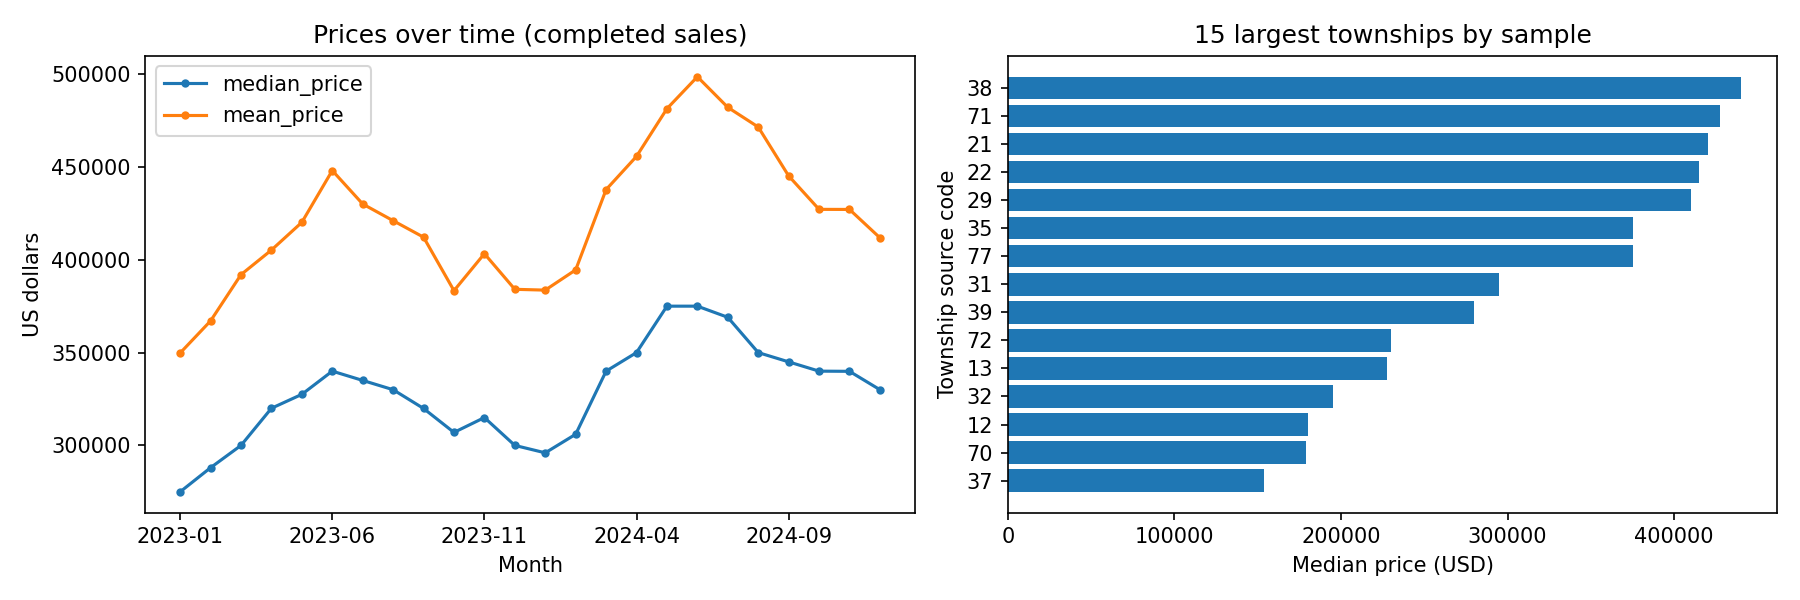

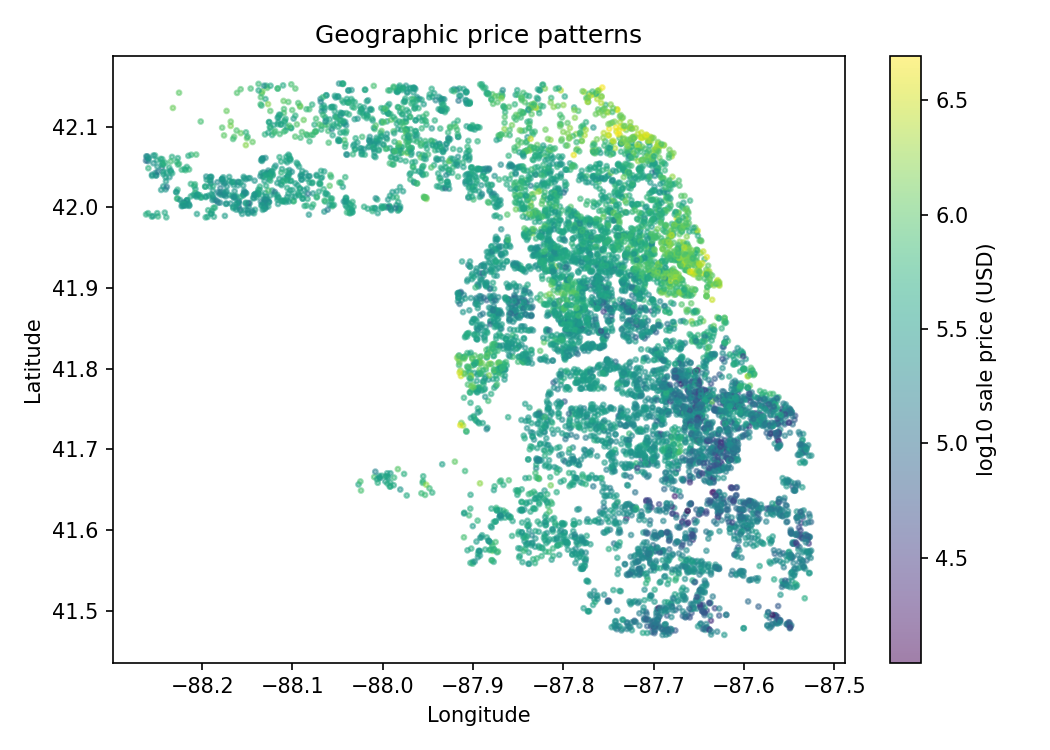

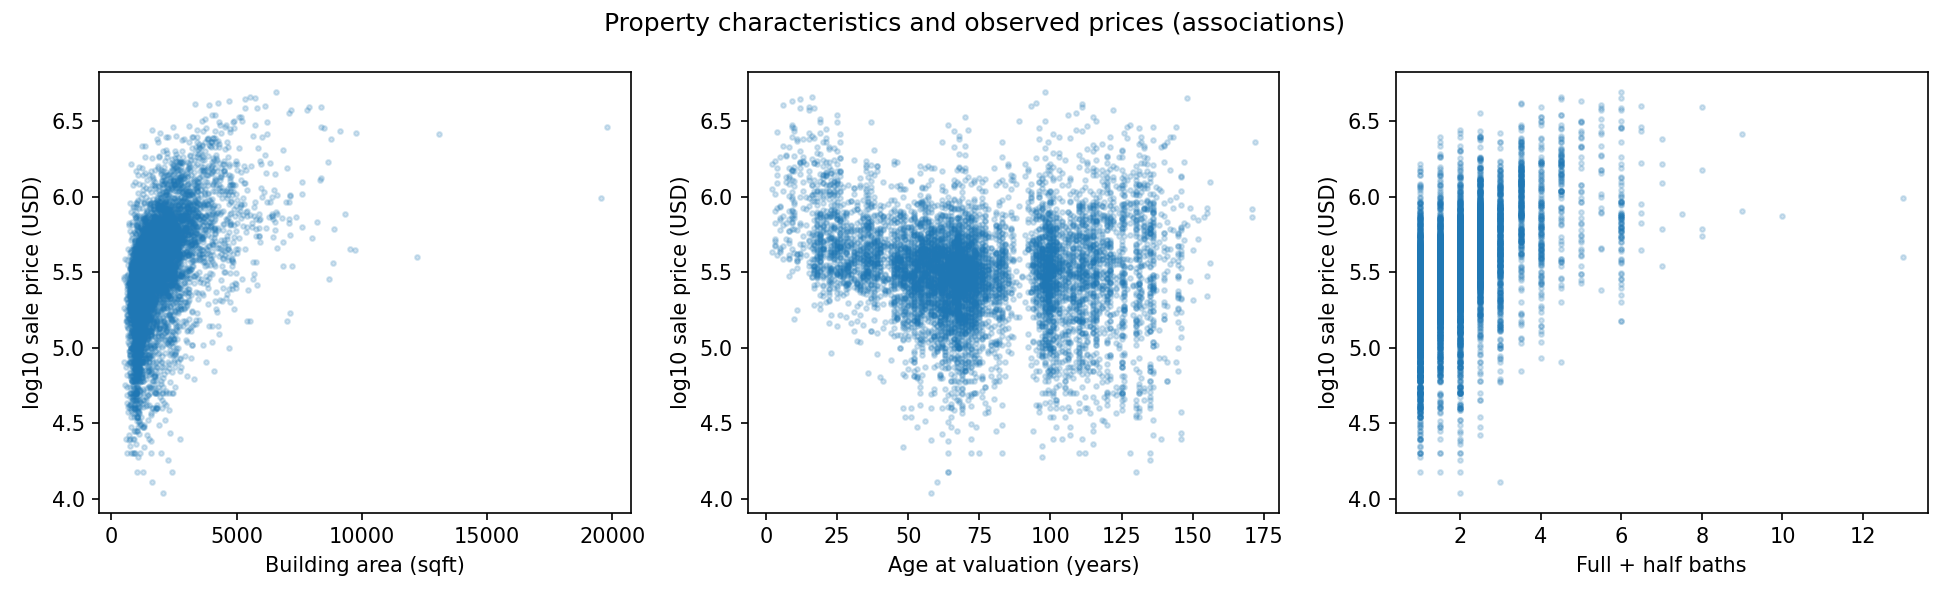

In [11]:
# EDA 使用清洗后的 development；图中抽样不改变训练数据或最终指标。

def eda(development, numeric, out, prefix='development'):
    # 2c: distributions, outliers and area summaries retained as evidence.
    d = development.copy()
    d['month'] = d.sale_date.dt.to_period('M').astype(str)
    monthly = d.groupby('month').agg(n=('sale_price', 'size'), median_price=('sale_price', 'median'),
                mean_price=('sale_price', 'mean'), median_building_sf=('char_bldg_sf', 'median'),
                median_age=('age_at_valuation', 'median'))
    monthly.to_csv(out / f'{prefix}_monthly_prices.csv')
    township = d.groupby('meta_township_code').agg(n=('sale_price', 'size'),
        median_price=('sale_price', 'median'), mean_price=('sale_price', 'mean'),
        median_building_sf=('char_bldg_sf', 'median'), median_age=('age_at_valuation', 'median'),
        median_baths=('total_bathrooms', 'median'))
    township.to_csv(out / f'{prefix}_township_prices.csv')
    d[numeric + NEW_NUMERIC].describe(percentiles=[.01, .5, .99]).T.to_csv(out / f'{prefix}_numeric_summary.csv')
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    monthly[['median_price', 'mean_price']].plot(ax=axes[0], marker='o', markersize=3)
    axes[0].set(title='Prices over time (completed sales)', ylabel='US dollars', xlabel='Month')
    top = township.nlargest(15, 'n').sort_values('median_price')
    axes[1].barh(top.index.astype(str), top.median_price)
    axes[1].set(title='15 largest townships by sample', xlabel='Median price (USD)', ylabel='Township source code')
    fig.tight_layout(); fig.savefig(out / f'{prefix}_prices.png', dpi=150); plt.close(fig)
    sample = d.sample(min(8000, len(d)), random_state=SEED)
    fig, ax = plt.subplots(figsize=(7, 5))
    plot = ax.scatter(sample.loc_longitude, sample.loc_latitude, c=np.log10(sample.sale_price), s=5, alpha=.5, cmap='viridis')
    fig.colorbar(plot, ax=ax, label='log10 sale price (USD)')
    ax.set(title='Geographic price patterns', xlabel='Longitude', ylabel='Latitude')
    fig.tight_layout(); fig.savefig(out / f'{prefix}_geography.png', dpi=150); plt.close(fig)
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for ax, col, label in zip(axes, ['char_bldg_sf', 'age_at_valuation', 'total_bathrooms'],
                             ['Building area (sqft)', 'Age at valuation (years)', 'Full + half baths']):
        ax.scatter(sample[col], np.log10(sample.sale_price), s=5, alpha=.2)
        ax.set(xlabel=label, ylabel='log10 sale price (USD)')
    fig.suptitle('Property characteristics and observed prices (associations)')
    fig.tight_layout(); fig.savefig(out / f'{prefix}_characteristics.png', dpi=150); plt.close(fig)

eda(development,numeric,OUT,prefix='development')
print(pd.read_csv(OUT/'development_monthly_prices.csv').head(6).to_string(index=False))
show_image(OUT/'development_prices.png')
show_image(OUT/'development_geography.png')
show_image(OUT/'development_characteristics.png')

## 5. 特征集合与训练期预处理

A：基本结构和 Township；B：物业／位置加新特征；C：全部归档变量加新特征。各模型在相同集合、切分与评价规则下比较。

**防泄漏关键**：不能先对全量 df 做中位数填补、标准化或学习稀有类别。下面的 Pipeline 只在 `fit(train)` 时学习这些统计，再用相同变换处理 validation/test；最终重训时只使用 train+validation。

In [12]:
def feature_sets(numeric, categorical, out):
    a_num = ['char_bldg_sf', 'char_land_sf', 'char_yrblt', 'char_beds', 'char_rooms', 'char_fbath', 'char_hbath']
    a_cat = ['char_type_resd', 'char_use', 'meta_class', 'meta_township_code']
    # 三个递增集合用于公平比较特征增益：基础、物业/位置、全部归档变量。
    # 不使用测试集选择变量；区域 Census 值描述区域，不代表个别业主。
    b_num = [c for c in numeric if c.startswith('char_') or c in ['loc_latitude', 'loc_longitude']] + NEW_NUMERIC
    b_cat = [c for c in categorical if c.startswith('char_') or c in
             ['meta_class', 'meta_cdu', 'meta_township_code', 'meta_nbhd_code', 'loc_property_city', 'loc_property_zip']]
    sets = {'A_basic': (a_num, a_cat), 'B_property_location': (b_num, b_cat),
            'C_all_archived': (numeric + NEW_NUMERIC, categorical)}
    for nums, cats in sets.values():
        assert not {'sale_price', 'property_id', 'transaction_id', 'row_id', 'sale_date'} & set(nums + cats)
    dump_json(out / 'feature_sets.json', {k: {'numeric': n, 'categorical': c} for k, (n, c) in sets.items()})
    return sets

sets = feature_sets(numeric,categorical,OUT)
print(pd.DataFrame([{'feature_set':k,'numeric':len(n),'categorical':len(c),'total':len(n)+len(c)}
                    for k,(n,c) in sets.items()]).to_string(index=False))

        feature_set  numeric  categorical  total
            A_basic        7            4     11
B_property_location       19           25     44
     C_all_archived       67           38    105


In [13]:
def preprocessing(nums, cats, spline=False, n_knots=4, degree=3, knots='uniform'):
    # 中位数由训练数据学习；缺失指示器保留某项信息未知的信号。
    imputer = lambda: SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)
    transforms = []
    spline_cols = [c for c in ['log_building_sf', 'age_at_valuation'] if c in nums] if spline else []
    if spline and not spline_cols:
        spline_cols = ['char_bldg_sf', 'char_yrblt']
    regular = [c for c in nums if c not in spline_cols]
    if regular:
        transforms.append(('numeric', Pipeline([('impute', imputer()), ('scale', StandardScaler())]), regular))
    if spline_cols:
        transforms.append(('spline', Pipeline([
            ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
            ('basis', SplineTransformer(n_knots=n_knots, degree=degree, knots=knots, include_bias=False)),
            ('scale', StandardScaler())]), spline_cols))
    # One-Hot 防止类别代码被解释成大小；频率阈值和类别上限控制维度。
    transforms.append(('category', OneHotEncoder(handle_unknown='infrequent_if_exist',
                        min_frequency=100, max_categories=20, sparse_output=False), cats))
    # 填补、标准化、稀有类别和样条节点均在 Pipeline 内拟合，验证/测试只变换。
    return ColumnTransformer(transforms, remainder='drop', sparse_threshold=0)

### 5.1 从 C 提取精选集 D：只使用 2023 训练数据

**目的**：在105个输入变量中形成一个可复现的公共精简集，检验数据成本与精度的取舍，不声称得到所有模型共同的最优子集。

**先定规则，再筛选**：内部拟合期为2023年1–9月，内部评估期为10–12月，并排除评估期中已在拟合期出现的物业。这里的内部评估仍属于原2023训练集；筛选函数不接收2024、2025数据。

1. 仅根据内部拟合期，删除缺失比例≥95%和整列恒定的变量。类别缺失标签与真实“不适用”代码区别处理；高缺失阈值是简化假设，缺失模式也可能包含信息。
2. 固定参数的Histogram Boosting拟合内部训练期。预处理也只在该时期fit。对内部评估期最多4000条固定随机抽样做3次原始变量置换，用主情景WAE的增加衡量预测依赖程度。
3. 在通过质量筛选的前提下，优先保留面积、房龄、卫浴、土地面积、镇区和房屋类型六项核心输入；再按正重要性从高到低加入，目标覆盖正重要性总和的95%，且总数最多40个。若预算先用尽，报告实际覆盖率。95%不是解释方差，也不代表显著性；40是预先规定的简化预算，未用2024挑选。

**输出**：C/D总数、数值/类别数、原始/新特征数、减少数量和比例、各信息组数量、105个变量逐项保留/删除理由及完整D清单。数量按编码前输入变量计算；one-hot/样条展开后的列数不同。

**限制**：单一选择器与单个内部时间窗口可能偏向某种非线性关系；相关变量可相互替代，低或负置换重要性不等于没有业务价值。被删除变量也可能与其他变量共同发挥作用。D是待检验的候选集。


内部划分： 29123 拟合； 7863 评估；排除跨期重复物业交易 534

精简前后数量（编码前）：
 feature_set  numeric  categorical  raw  engineered  total  removed_vs_C  reduction_pct
          C       67           38   97           8    105             0           0.00
          D        9            5   11           3     14            91          86.67

各信息组数量：
 information_group  C_count  D_count  removed
   community_acs5       22        1       21
       engineered        8        3        5
location_metadata       26        4       22
         property       28        6       22
        proximity       18        0       18
 tax_school_other        3        0        3

D保留变量： ['loc_longitude', 'loc_latitude', 'char_yrblt', 'char_bldg_sf', 'char_land_sf', 'acs5_median_household_owner_occupied_value', 'age_at_valuation', 'total_bathrooms', 'log_building_sf', 'char_type_resd', 'char_bsmt', 'char_use', 'meta_class', 'meta_township_code']

置换重要性前15：
                                               feature  importance_mean  impor

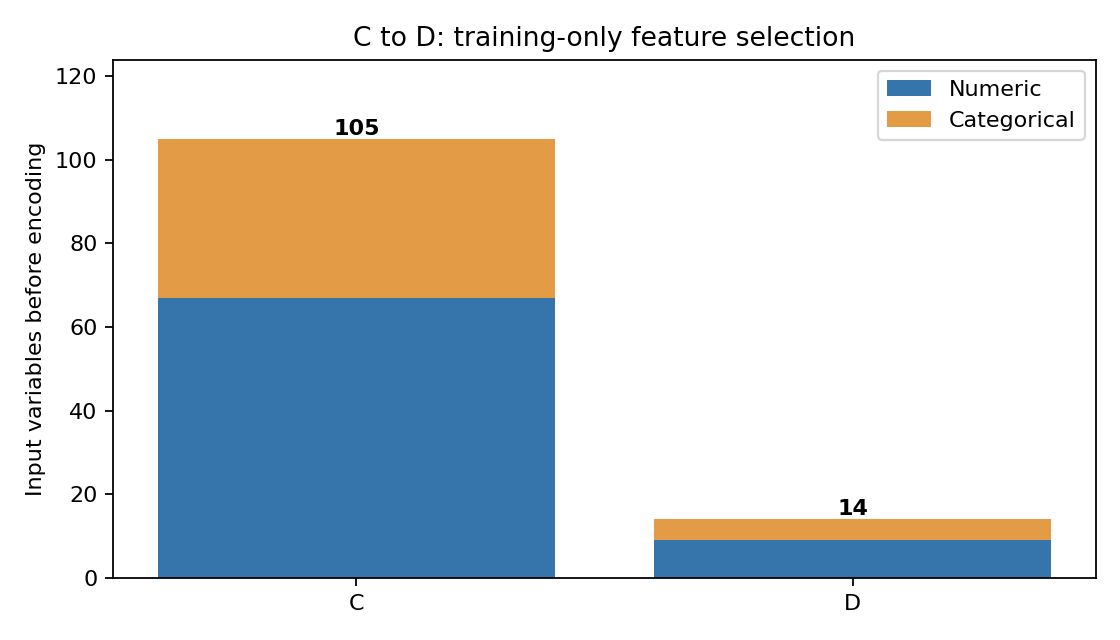

In [23]:
def select_features_2023(train_2023, c_set, out):
    """只读取2023，先定规则再执行；D是预算约束的候选集，不声称全局最优。"""
    assert train_2023.sale_date.dt.year.eq(2023).all()
    nums, cats = c_set
    columns = nums + cats
    # 规则在计算重要性前固定，不依据2024/2025误差修改。
    plan = dict(source_year=2023, inner_fit='Jan-Sep', inner_score='Oct-Dec; property-disjoint',
                missing_threshold=0.95, max_features=40, positive_importance_coverage=0.95,
                importance_repeats=3, importance_sample_max=4000, seed=SEED,
                protected_features=['log_building_sf','age_at_valuation','total_bathrooms',
                                    'char_land_sf','meta_township_code','char_type_resd'],
                selector_model=dict(max_iter=120, learning_rate=0.08, max_leaf_nodes=15,
                                    min_samples_leaf=40, l2_regularization=10.0),
                purpose='common compact D; not per-family optimal; no 2024/2025 selection input')
    dump_json(out/'D_selection_plan.json', plan)
    fit = train_2023.loc[train_2023.sale_date.dt.month.le(9)].copy()
    late = train_2023.loc[train_2023.sale_date.dt.month.ge(10)].copy()
    check = late.loc[~late.property_id.isin(fit.property_id)].copy()
    assert not set(fit.property_id) & set(check.property_id)
    assert len(fit)>0 and len(check)>0
    # 去除重复物业仅针对两个内部时期之间的重叠；不按售价删除交易。
    pd.concat([fit[['row_id']].assign(role='inner_fit'),
               check[['row_id']].assign(role='inner_score')]).to_csv(out/'D_internal_split_ids.csv',index=False)
    rows=[]
    for col in columns:
        x=fit[col]
        missing=x.isna() | x.eq('__MISSING_OR_NA__')
        frac=float(missing.mean())
        distinct=int(x.loc[~missing].nunique())
        # 缺失本身可能有信息：仅在连缺失状态也恒定时按恒定删除。
        constant=int(x.nunique(dropna=False)) <= 1
        reason='missing_ge_95pct' if frac>=plan['missing_threshold'] else ('constant' if constant else '')
        rows.append(dict(feature=col,kind='numeric' if col in nums else 'categorical',
                         missing_fraction_inner_fit=frac,distinct_nonmissing=distinct,
                         filter_reason=reason))
    audit_d=pd.DataFrame(rows)
    eligible=audit_d.loc[audit_d.filter_reason.eq(''),'feature'].tolist()
    en=[c for c in nums if c in eligible]; ec=[c for c in cats if c in eligible]
    # 预处理仅fit 2023年1-9月；类别变量按原始整列打乱，避免拆散one-hot类别。
    selector=TransformedTargetRegressor(
        regressor=Pipeline([('preprocess',preprocessing(en,ec)),
            ('regressor',HistGradientBoostingRegressor(random_state=SEED,early_stopping=False,
                                                       **plan['selector_model']))]),
        func=np.log1p,inverse_func=np.expm1,check_inverse=False)
    selector.fit(fit[eligible],fit.sale_price)
    sample=check.sample(min(len(check),plan['importance_sample_max']),random_state=SEED)
    def negative_main_wae(estimator,x,y):
        error=np.maximum(estimator.predict(x),0)-np.asarray(y)
        return -float(np.mean(np.abs(error)*np.where(error>0,MAIN_WEIGHTS[0],MAIN_WEIGHTS[1])))
    importance=permutation_importance(selector,sample[eligible],sample.sale_price,
        scoring=negative_main_wae,n_repeats=plan['importance_repeats'],random_state=SEED,n_jobs=1)
    ranks=pd.DataFrame(dict(feature=eligible,importance_mean=importance.importances_mean,
                            importance_std=importance.importances_std))
    ranks=ranks.sort_values(['importance_mean','feature'],ascending=[False,True])
    # 六个可用核心变量优先保留，保证基础结构和样条输入；其余按正重要性递增入选。
    # 95%只是正重要性总和覆盖目标，不是解释方差、显著性或统计等效。
    positive=ranks.loc[ranks.importance_mean.gt(0)].copy()
    weights=dict(zip(positive.feature,positive.importance_mean))
    selected=[c for c in plan['protected_features'] if c in eligible]
    total=float(positive.importance_mean.sum())
    target=plan['positive_importance_coverage']*total
    for col in positive.feature:
        if sum(weights.get(c,0.) for c in selected)>=target or len(selected)>=plan['max_features']:
            break
        if col not in selected: selected.append(col)
    if not selected: raise ValueError('无可用D变量；应检查内部时期和数据，不自动借用外部验证集。')
    # 保持原C列顺序；D只包含C的子集，不会新增标签或ID。
    dn=[c for c in nums if c in selected]; dc=[c for c in cats if c in selected]
    audit_d=audit_d.merge(ranks,on='feature',how='left')
    audit_d['kept_in_D']=audit_d.feature.isin(selected)
    def reason(row):
        if row.filter_reason:return row.filter_reason
        if row.kept_in_D:return 'protected_core' if row.feature in plan['protected_features'] else 'positive_importance_selected'
        return 'nonpositive_importance' if row.importance_mean<=0 else 'outside_coverage_or_budget'
    audit_d['decision_reason']=audit_d.apply(reason,axis=1)
    def group(col):
        if col in NEW_NUMERIC:return 'engineered'
        if col.startswith('char_'):return 'property'
        if col.startswith('acs5_'):return 'community_acs5'
        if col.startswith('prox_'):return 'proximity'
        if col.startswith('other_'):return 'tax_school_other'
        return 'location_metadata'
    audit_d['information_group']=audit_d.feature.map(group)
    # 补上字典说明，使每个保留/删除决定可追溯；工程变量在代码中有定义。
    dictionary=pd.read_csv(out/'source_feature_dictionary.csv')
    audit_d=audit_d.merge(dictionary[['variable','label','definition']],left_on='feature',right_on='variable',how='left')
    audit_d.to_csv(out/'C_to_D_feature_decisions.csv',index=False)
    count=pd.DataFrame([dict(feature_set=k,numeric=len(ns),categorical=len(cs),
         raw=sum(c not in NEW_NUMERIC for c in ns+cs),engineered=sum(c in NEW_NUMERIC for c in ns+cs),
         total=len(ns)+len(cs)) for k,(ns,cs) in [('C',c_set),('D',(dn,dc))]])
    count['removed_vs_C']=len(columns)-count.total
    count['reduction_pct']=100*count.removed_vs_C/len(columns)
    count.to_csv(out/'C_vs_D_feature_counts.csv',index=False)
    grouped=audit_d.groupby('information_group').agg(C_count=('feature','size'),D_count=('kept_in_D','sum')).reset_index()
    grouped['removed']=grouped.C_count-grouped.D_count
    grouped.to_csv(out/'C_vs_D_group_counts.csv',index=False)
    achieved=sum(weights.get(c,0.) for c in selected)/total if total>0 else None
    manifest=dict(plan=plan,inner_fit_rows=len(fit),inner_score_rows=len(check),
        inner_overlap_excluded=len(late)-len(check),importance_sample_rows=len(sample),
        numeric=dn,categorical=dc,n_features=len(selected),positive_importance_coverage_achieved=achieved,
        used_2024=False,used_2025=False)
    dump_json(out/'D_selection_manifest.json',manifest)
    dump_json(out/'feature_set_D.json',dict(numeric=dn,categorical=dc))
    fig,ax=plt.subplots(figsize=(7,4))
    ax.bar(count.feature_set,count.numeric,label='Numeric',color='#3575ab')
    ax.bar(count.feature_set,count.categorical,bottom=count.numeric,label='Categorical',color='#e49b45')
    for i,row in count.iterrows(): ax.text(i,row.total+1,str(row.total),ha='center',fontweight='bold')
    ax.set(ylabel='Input variables before encoding',title='C to D: training-only feature selection',ylim=(0,len(columns)*1.18))
    ax.legend();fig.tight_layout();fig.savefig(out/'C_vs_D_feature_counts.png',dpi=160);plt.close(fig)
    print('内部划分：',len(fit),'拟合；',len(check),'评估；排除跨期重复物业交易',len(late)-len(check))
    print('\n精简前后数量（编码前）：\n',count.round(2).to_string(index=False))
    print('\n各信息组数量：\n',grouped.to_string(index=False))
    print('\nD保留变量：',dn+dc)
    print('\n置换重要性前15：\n',ranks.head(15).round(2).to_string(index=False))
    print('\n正重要性覆盖率（非解释方差）：',achieved)
    return (dn,dc),audit_d,count

D_features,D_decisions,D_counts=select_features_2023(train,sets['C_all_archived'],OUT)
# 单独保存，不修改原A/B/C实验的sets，避免把D意外加入旧的调参和冻结流程。
sets_with_D={**sets,'D_selected':D_features}
show_image(OUT/'C_vs_D_feature_counts.png')


**本次执行结果：C → D 从105个精简为14个输入变量，删除91个，减少86.67%。**

| 编码前变量口径 | C | D | 减少 |
|---|---:|---:|---:|
| 总数 | 105 | 14 | 91 |
| 数值 | 67 | 9 | 58 |
| 类别 | 38 | 5 | 33 |
| 原始变量 | 97 | 11 | 86 |
| 工程变量 | 8 | 3 | 5 |

D的3个工程变量为估值时房龄、总卫浴数、建筑面积对数。11个原始变量包括经纬度、建造年份、建筑面积、土地面积、社区业主住房价值中位数、房屋类型、地下室、用途、评估类别和镇区代码。社区住房价值是原始归档中的区域统计值，不是根据2023–2025交易价格新计算的目标编码。

删除理由分布：2个变量达到高缺失阈值；52个在此次选择器下的重要性不为正；37个未进入覆盖目标所需的子集。最终保留6个核心变量和8个按正重要性补充的变量，覆盖此次正重要性总和的95.21%。这些比例不能解读为价格解释率。

原始面积/对数面积、建造年份/估值时房龄仍有信息重叠：为了兼顾共同特征集的业务含义与不同模型表达形式，核心变量未因重要性偏低自动剔除。D并非最小无冗余集合。交通、学校等组未入选，也不能推出它们没有业务或因果价值。


## 6. Evaluation metrics, simple baselines and candidate models

MSE is lower-is-better and measured in squared dollars; R² is higher-is-better and can be negative; MAE is lower-is-better and measured in dollars. All three are calculated from actual sale prices and predictions in original-dollar units. WAE remains a separate business-weighted selection measure.

The constant median baseline uses no property inputs; the 1/3 quantile baseline is included as a cost-aligned constant prediction for the 2:1 overvaluation/undervaluation priority. These weights are priorities, not actual tax costs.

Saved outputs in this notebook were produced before the metric update. Rerun the relevant development cells to regenerate comparisons with MSE, R² and MAE; this source update does not refit models or use 2025 for selection.

Split consistency note: this modeling notebook excludes properties seen in 2023 from its 2024 validation set (32,967 transactions) and properties seen in development from its 2025 test set (32,335 of 36,322 transactions). Validation.ipynb evaluates all 35,465 transactions in 2024. These are different evaluation populations; resolve the split design before cross-notebook conclusions or final test reporting.

In [14]:
def wae(y, pred, weights=MAIN_WEIGHTS):
    """Average weighted dollar error over ALL sales, not normalized by weight sum."""
    error = np.asarray(pred) - np.asarray(y)
    # Multiply each transaction's absolute error by its directional weight, then average across transactions.
    return float(np.mean(np.abs(error) * np.where(error > 0, weights[0], weights[1])))

def metrics(y, pred):
    y, pred = np.asarray(y), np.asarray(pred)
    error = pred - y  # Positive values indicate overvaluation; negative values indicate undervaluation.
    return {'n': len(y), 'MSE': mean_squared_error(y, pred),
            'R2': r2_score(y, pred), 'MAE': mean_absolute_error(y, pred),
            'WAE_main': wae(y, pred), 'mean_signed_error': float(error.mean()),
            'median_APE': float(np.median(np.abs(error) / y)),
            'overvaluation_rate': float(np.mean(error > 0)),
            'within_20pct': float(np.mean(np.abs(error) / y <= .2))}

def predict_price(model, x):
    # Inverse-transform log-price models and apply the same non-negative price constraint to every model.
    pred = np.maximum(np.asarray(model.predict(x), dtype=float), 0.)
    if not np.isfinite(pred).all(): raise ValueError('Nonfinite price prediction.')
    return pred

# Manual example: (20 × 2 + 30 × 1 + 0) / 3 = 23.3333.
assert np.isclose(wae([100,100,100],[120,70,100]),70/3)
print('WAE direction and manual calculation check passed.')

WAE 方向与计算手工例子检查通过。


七种回归方法：OLS、Ridge、Lasso、样条 Ridge、决策树、随机森林、Histogram Gradient Boosting。目标主要用 log1p 压缩偏态，并加入原美元目标 Boosting 对照；不假设反变换后的预测一定是无偏条件均值。

复杂度控制包括惩罚强度、有限的样条节点、树深／叶节点样本数、树数、Boosting 叶数／迭代数／L2。保留旧版 32 个候选作为起点，并加入有限、可复现的网格／随机搜索与局部细化。所有参数结果保留，不只展示胜出配置。Boosting 关闭内部随机早停，统一使用物业不重叠的年度验证集。

In [15]:
def model_for(spec, sets):
    """按实验配置创建一个独立 Pipeline，保持预处理参数只从训练数据学习。"""
    nums, cats = sets[spec['feature_set']]
    family, params = spec['family'], spec['params'].copy()
    # 样条参数属于特征变换器；alpha 属于 Ridge，不能全部传给 Ridge。
    spline_options = {k: params.pop(k) for k in ['n_knots', 'degree', 'knots'] if k in params}
    if family == 'OLS':
        reg = LinearRegression()
    elif family in ['Ridge', 'SplineRidge']:
        reg = Ridge(**params)
    elif family == 'Lasso':
        reg = Lasso(max_iter=15000, tol=1e-4, **params)
    elif family == 'DecisionTree':
        reg = DecisionTreeRegressor(random_state=SEED, **params)
    elif family == 'RandomForest':
        reg = RandomForestRegressor(random_state=SEED, n_jobs=2, **params)
    elif family == 'HistBoost':
        # 不启用内部随机早停；用固定的年度验证集选择迭代数。
        reg = HistGradientBoostingRegressor(random_state=SEED, early_stopping=False, **params)
    else:
        raise ValueError(family)
    pipe = Pipeline([('preprocess', preprocessing(nums, cats, family == 'SplineRidge', **spline_options)),
                     ('regressor', reg)])
    if spec['target'] == 'log':
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1, check_inverse=False)
    return pipe

def specs_for(sets):
    specs = []
    defaults = {
        'OLS': {}, 'Ridge': {'alpha': 10.}, 'Lasso': {'alpha': .001},
        'SplineRidge': {'alpha': 10.},
        'DecisionTree': {'max_depth': 8, 'min_samples_leaf': 100},
        'RandomForest': {'n_estimators': 60, 'max_depth': 14, 'min_samples_leaf': 20, 'max_features': .7},
        'HistBoost': {'max_iter': 160, 'learning_rate': .08, 'max_leaf_nodes': 15,
                      'min_samples_leaf': 40, 'l2_regularization': 10.}}
    def add(family, feature_set, params, target='log', phase='feature_comparison'):
        specs.append({'candidate_id': f'M{len(specs)+1:02}', 'family': family,
                      'feature_set': feature_set, 'params': params, 'target': target,
                      'phase': phase})
    for fs in sets:
        for family, params in defaults.items(): add(family, fs, params.copy())
    # Small PREDECLARED search, rather than a huge unrestricted grid.
    for alpha in [.1, 100.]: add('Ridge', 'C_all_archived', {'alpha': alpha}, phase='tuning')
    for alpha in [.0001, .01]: add('Lasso', 'C_all_archived', {'alpha': alpha}, phase='tuning')
    add('SplineRidge', 'C_all_archived', {'alpha': 100.}, phase='tuning')
    for depth, leaf in [(5, 200), (12, 30)]:
        add('DecisionTree', 'C_all_archived', {'max_depth': depth, 'min_samples_leaf': leaf}, phase='tuning')
    add('RandomForest', 'C_all_archived', {'n_estimators': 80, 'max_depth': 18,
         'min_samples_leaf': 10, 'max_features': .7}, phase='tuning')
    for leaves, iterations in [(7, 120), (31, 240)]:
        par = defaults['HistBoost'].copy(); par.update(max_leaf_nodes=leaves, max_iter=iterations)
        add('HistBoost', 'C_all_archived', par, phase='tuning')
    add('HistBoost', 'C_all_archived', defaults['HistBoost'].copy(), target='raw', phase='target_experiment')
    return specs

In [21]:
FAMILY_ORDER = ['OLS', 'Ridge', 'Lasso', 'SplineRidge', 'DecisionTree', 'RandomForest', 'HistBoost']


def validation_spec_signature(spec):
    """缓存必须属于同一个模型、特征集、目标变换与参数，不能混用旧配置。"""
    return json.dumps({k: spec[k] for k in ['family', 'feature_set', 'params', 'target']}, sort_keys=True)


def save_validation_cache(out, spec, pred, valid):
    folder = out/'candidate_validation_predictions'
    folder.mkdir(exist_ok=True)
    index_path = folder/'validation_row_ids.csv'
    if not index_path.exists():
        valid[['row_id']].to_csv(index_path, index=False)
    # 保存验证预测，之后绘图直接复用，避免为了画图重复训练所有候选。
    np.savez_compressed(folder/f"{spec['candidate_id']}.npz", prediction=np.asarray(pred),
                        signature=np.asarray(validation_spec_signature(spec)))


def select_curve_candidates(all_results, champions):
    """只从已完成的实验中取代表配置，不新增调参或改变已选模型。"""
    table = all_results.loc[all_results.phase.ne('baseline')].copy()
    table['parsed_params'] = table.params.map(json.loads)
    selected, labels = {}, {}
    def find(family, **wanted):
        subset = table.loc[table.family.eq(family) & table.feature_set.eq('C_all_archived') & table.target.eq('log')]
        subset = subset.loc[subset.parsed_params.map(lambda p: all(p.get(k, None) == v for k,v in wanted.items()))]
        return None if subset.empty else subset.sort_values('candidate_id').iloc[0]
    for family in FAMILY_ORDER:
        best = champions.loc[champions.family.eq(family)].iloc[0]
        best_params = json.loads(best.params)
        rows = []
        if family == 'OLS':
            rows = [best]
        elif family == 'Ridge':
            rows = [find(family, alpha=x) for x in [.1, 10., 100.]]
        elif family == 'Lasso':
            rows = [find(family, alpha=x) for x in [.0001, .001, .01]]
        elif family == 'SplineRidge':
            # 节点数逐步变化；阶数和 alpha 固定于冠军设置。
            rows = [find(family, n_knots=x, degree=best_params.get('degree',3), alpha=best_params['alpha'])
                    for x in [3,5,7]]
        elif family == 'DecisionTree':
            # 现有实验的深度和叶大小共同变化；不是只改变深度的受控实验。
            rows = [find(family,max_depth=5,min_samples_leaf=200),
                    find(family,max_depth=8,min_samples_leaf=100),
                    best,find(family,max_depth=None,min_samples_leaf=20)]
        elif family == 'RandomForest':
            fixed = {k:v for k,v in best_params.items() if k != 'n_estimators'}
            rows = [find(family,n_estimators=x,**fixed) for x in [60,120,240]]
        elif family == 'HistBoost':
            fixed = {k:v for k,v in best_params.items() if k != 'max_iter'}
            rows = [find(family,max_iter=x,**fixed) for x in [120,240,400,600]]
        rows = [r for r in rows if r is not None]
        if not any(r.candidate_id == best.candidate_id for r in rows): rows.append(best)
        unique = {r.candidate_id:r for r in rows}
        selected[family] = list(unique)
        for candidate_id, row in unique.items():
            p = json.loads(row.params)
            if family in ['Ridge','Lasso']: label=f"alpha={p['alpha']:g}"
            elif family == 'SplineRidge': label=f"knots={p.get('n_knots',4)}, degree={p.get('degree',3)}, a={p['alpha']:g}"
            elif family == 'DecisionTree': label=f"depth={p.get('max_depth','None')}, leaf={p.get('min_samples_leaf',1)}"
            elif family == 'RandomForest': label=f"trees={p['n_estimators']}"
            elif family == 'HistBoost': label=f"rounds={p['max_iter']}"
            else: label='OLS (no tuning)'
            labels[candidate_id]=label
    return selected, labels


def plot_best_models_and_parameter_curves(train, valid, sets, out):
    """所有图使用 2024 验证数据；不对 2025 的模型表现重新选优。"""
    from sklearn.base import clone
    from collections import OrderedDict
    results = pd.read_csv(out/'validation_results.csv')
    champions = pd.read_csv(out/'best_model_per_family.csv')
    selected, labels = select_curve_candidates(results, champions)
    ids = [cid for family in FAMILY_ORDER for cid in selected[family]]
    requested = results.loc[results.candidate_id.isin(ids)].copy()
    requested.to_csv(out/'plot_candidate_parameters.csv', index=False)
    pred_by_id = {}
    cache = OrderedDict()
    prediction_folder = out/'candidate_validation_predictions'
    if (prediction_folder/'validation_row_ids.csv').exists():
        cached_ids = pd.read_csv(prediction_folder/'validation_row_ids.csv', dtype=str).row_id.tolist()
        assert cached_ids == valid.row_id.tolist(), '缓存预测与当前验证交易顺序不一致。'
    for _, row in requested.iterrows():
        spec = {'candidate_id':row.candidate_id, 'family':row.family, 'feature_set':row.feature_set,
                'params':json.loads(row.params), 'target':row.target}
        saved = prediction_folder/f'{row.candidate_id}.npz'
        if saved.exists():
            with np.load(saved, allow_pickle=False) as z:
                assert z['signature'].item() == validation_spec_signature(spec)
                pred = z['prediction'].copy()
        else:
            # 旧版本未保存逐候选验证预测时，只重建本图需要的已评估配置。
            # 不重跑搜索、不新增配置、不比较测试成绩。
            nums, cats = sets[spec['feature_set']]
            opts = {k:spec['params'].get(k,v) for k,v in [('n_knots',4),('degree',3),('knots','uniform')]} if row.family=='SplineRidge' else {}
            key = (spec['feature_set'], json.dumps(opts,sort_keys=True))
            if key not in cache:
                pre = preprocessing(nums,cats,row.family=='SplineRidge',**opts)
                cache[key] = (pre.fit_transform(train[nums+cats]),pre.transform(valid[nums+cats]))
                if len(cache)>2:cache.popitem(last=False)
            xt,xv = cache[key]
            full = model_for(spec,sets)
            pipe = full.regressor if row.target=='log' else full
            reg = clone(pipe.named_steps['regressor'])
            reg.fit(xt,np.log1p(train.sale_price.to_numpy()) if row.target=='log' else train.sale_price.to_numpy())
            pred = reg.predict(xv)
            if row.target=='log':pred=np.expm1(pred)
            pred = np.maximum(pred,0.)
            save_validation_cache(out,spec,pred,valid)
        # 验证绘图使用的确实是之前那组模型的预测，不是重新调出来的新结果。
        assert len(pred)==len(valid) and np.isfinite(pred).all()
        assert np.isclose(wae(valid.sale_price,pred),row.WAE_main,rtol=1e-6), row.candidate_id
        pred_by_id[row.candidate_id]=pred
        print('绘图预测已核对：',row.candidate_id,row.family,labels[row.candidate_id],flush=True)
    cache.clear()
    frame = valid[['row_id','sale_date','sale_price','char_bldg_sf']].copy().reset_index(drop=True)
    frame['month']=frame.sale_date.dt.to_period('M').astype(str)
    for cid,pred in pred_by_id.items():frame[cid]=pred
    months = frame.groupby('month',sort=True).size().index.tolist()
    monthly_bounds=frame.groupby('month')[['sale_price']+champions.candidate_id.tolist()].mean()/1000
    monthly_limits=(max(0,float(monthly_bounds.min().min())*.96),float(monthly_bounds.max().max())*1.04)
    plots = out/'model_comparison_plots';plots.mkdir(exist_ok=True)
    palette = ['#3366AA','#36946C','#B37B27','#8055A2','#4C9097']
    monthly_tables=[]

    def monthly_panel(ax,family):
        champion=champions.loc[champions.family.eq(family)].iloc[0]
        g=frame.groupby('month',sort=True).agg(n=('sale_price','size'),actual_mean=('sale_price','mean'),
                    predicted_mean=(champion.candidate_id,'mean'))
        g['family']=family;g['candidate_id']=champion.candidate_id
        x=np.arange(len(g))
        ax.plot(x,g.actual_mean/1000,color='#222222',lw=2,marker='o',ms=3,label='Actual mean')
        ax.plot(x,g.predicted_mean/1000,color='#C63E3B',lw=2.5,marker='o',ms=3,label='Best-model predicted mean')
        ax.set(title=f'{family} | {champion.candidate_id}',ylabel='Mean price (USD thousands)',
               xlabel='Validation month (2024)')
        ax.set_xticks(x[::2],g.index.str[-2:][::2]);ax.grid(alpha=.2);ax.legend(fontsize=8)
        ax.set_ylim(*monthly_limits)
        ax.tick_params(axis='x',labelbottom=True)
        return g.reset_index()

    fig,axes=plt.subplots(2,4,figsize=(18,9),sharex=True,sharey=True)
    for ax,family in zip(axes.ravel(),FAMILY_ORDER):
        monthly_tables.append(monthly_panel(ax,family))
    axes.ravel()[-1].axis('off')
    axes.ravel()[-1].text(.04,.9,'Same 2024 validation sales for every model.\n\nEach point is a monthly mean, not an individual\nhouse forecast or a separate market index.\n\nParameters were selected on validation WAE;\nmonthly averaging can hide large individual errors.',va='top',fontsize=11,linespacing=1.6,transform=axes.ravel()[-1].transAxes)
    fig.suptitle('Best model in each family vs actual monthly sale prices (validation)',fontsize=16)
    fig.tight_layout(rect=[0,0,1,.96]);fig.subplots_adjust(hspace=.38);fig.savefig(out/'best_models_actual_monthly.png',dpi=160);plt.close(fig)
    pd.concat(monthly_tables,ignore_index=True).to_csv(out/'best_models_actual_monthly.csv',index=False)
    for family in FAMILY_ORDER:
        fig,ax=plt.subplots(figsize=(8,4.5));monthly_panel(ax,family)
        fig.tight_layout();fig.savefig(plots/f'{family}_actual_monthly.png',dpi=180);plt.close(fig)

    # 多变量模型不能像单变量多项式一样直接画唯一的 y=f(面积)。
    # 此处对同一批真实验证房屋按面积分箱，对各配置的预测取同样的箱内均值。
    # 这保留了真实房屋组合；不是控制其他变量后的因果/净效应，也不是偏依赖图。
    frame['area_bin']=pd.qcut(frame.char_bldg_sf,q=20,duplicates='drop')
    usable=frame.loc[frame.area_bin.notna()].copy()
    raw=usable.sample(min(1600,len(usable)),random_state=SEED)
    scatter_max=usable.sale_price.quantile(.99)
    raw=raw.loc[raw.sale_price<=scatter_max]  # 只过滤灰色散点的显示，分组曲线仍包含全部有效面积样本
    area_tables=[]
    def parameter_panel(ax,family):
        best_id=champions.loc[champions.family.eq(family),'candidate_id'].iloc[0]
        group=usable.groupby('area_bin',observed=True,sort=True)
        actual=group.agg(area_median=('char_bldg_sf','median'),actual_mean=('sale_price','mean'),n=('sale_price','size'))
        ax.scatter(raw.char_bldg_sf,raw.sale_price/1000,s=5,alpha=.08,color='#777777',rasterized=True)
        ax.plot(actual.area_median,actual.actual_mean/1000,'--',color='#222222',lw=1.5,label='Actual bin mean',zorder=4)
        # 先画普通候选，再把最优曲线放到最上层，避免细线遮住粗红线。
        ordinary=[cid for cid in selected[family] if cid!=best_id]
        for i,cid in enumerate(ordinary+[best_id]):
            g=group[cid].mean()
            best=cid==best_id
            ax.plot(actual.area_median,g/1000,color='#D62F2F' if best else palette[i%len(palette)],
                    lw=3.2 if best else 1.2,alpha=1 if best else .8,zorder=6 if best else 3,
                    label=('BEST: ' if best else '')+labels[cid])
            area_tables.append(pd.DataFrame({'family':family,'candidate_id':cid,'best_in_family':best,
                'area_median':actual.area_median.to_numpy(),'n':actual.n.to_numpy(),
                'actual_mean':actual.actual_mean.to_numpy(),'predicted_mean':g.to_numpy()}))
        ax.set(title=family,xlabel='Building area (square feet)',ylabel='Price (USD thousands)')
        # 横轴显示曲线覆盖的分箱中位数范围；不删除任何用于箱内平均的交易。
        ax.set_xlim(max(0,actual.area_median.min()*.8),actual.area_median.max()*1.03)
        ax.grid(alpha=.2);ax.legend(fontsize=7,loc='upper left')
    fig,axes=plt.subplots(2,4,figsize=(19,10),sharey=True)
    for ax,family in zip(axes.ravel(),FAMILY_ORDER):parameter_panel(ax,family)
    axes.ravel()[-1].axis('off')
    axes.ravel()[-1].text(.03,.94,'Red thick line: selected family champion.\nThin lines: previously evaluated alternatives.\nDashed: actual mean in the same area bins.\n\nThese are binned multivariable predictions,\nNOT a one-feature fitted function or PDP.\n\nTree candidates vary depth AND leaf size.\nOLS has no tuning parameter.\n\nGrey points: sample, below p99 for display.\nAll area-valid sales enter every bin mean.',va='top',fontsize=10,linespacing=1.6,transform=axes.ravel()[-1].transAxes)
    fig.suptitle('Different parameter configurations: validation prediction curves; selected best in bold red',fontsize=15)
    fig.tight_layout(rect=[0,0,1,.96]);fig.subplots_adjust(hspace=.35);fig.savefig(out/'parameter_prediction_curves.png',dpi=160);plt.close(fig)
    # 单独图片调用也会追加 area_tables；在调用之前保存唯一的合图底层数据。
    pd.concat(area_tables,ignore_index=True).to_csv(out/'parameter_prediction_curves.csv',index=False)
    for family in FAMILY_ORDER:
        fig,ax=plt.subplots(figsize=(8,5));parameter_panel(ax,family)
        fig.tight_layout();fig.savefig(plots/f'{family}_parameter_curves.png',dpi=180);plt.close(fig)
    dump_json(out/'plot_verification.json',{'status':'passed','n_candidates':len(requested),
        'n_families':7,'validation_rows':len(valid),'monthly_includes_all_validation_rows':True,
        'area_excluded_missing_building_sf':int(frame.char_bldg_sf.isna().sum()),
        'candidate_predictions_match_recorded_validation_WAE':True,'new_parameter_search':False,
        'test_data_used_for_plots':False,'best_configuration_unchanged':True})
    return pd.concat(monthly_tables,ignore_index=True),requested


## 7. 依课件思路逐模型调参、族内选优与冻结

1. 先保留七种模型在 A/B/C 的 21 组公平特征实验及旧版参数起点。
2. 在 C 特征集扩展参数搜索：Spline Ridge 搜索节点数／阶数／alpha；Decision Tree 搜索深度、叶样本数与训练期剪枝路径；Random Forest 固定种子随机搜索结构后细化树数；Histogram Boosting 联合搜索学习率、叶数、轮数和正则化，再细化轮数。
3. 每个模型族从所有已测试配置中按**2024 验证主 WAE 最小**选出一名冠军，七名冠军与两个常数基准进入 `model_comparison_final.csv`。不再使用原来的 0.5% 容差或人为模型族复杂度排序。
4. 完整候选日志、参数、训练／验证误差、调参前后差异和轨迹图用于展示优化过程。`best_model_per_family.csv` 给出每族最佳参数；最终模型由冠军间的最小验证主 WAE 决定。
5. 完整 Pipeline 与缓存加速实现的验证成绩要一致，随后解释重要性并写入 `model_lock.json`，再进行最终重训与测试。

**课件对应及必要改动**：

| 课件 | 保留的调参思想 | 本作业的实现与差异 |
|---|---|---|
| 07 Regularisation | 搜索惩罚强度，用验证成绩作选择 | alpha 为回归模型的惩罚强度；不复制分类的 log-loss |
| 08 GAM | 比较样条阶数／节点，调节惩罚 | SplineTransformer + Ridge；不是 pyGAM 的相同平滑惩罚 |
| 09 Trees / RF | 训练集剪枝路径、网格／Optuna 参数搜索 | 回归树 ccp_alpha 路径；森林用固定种子随机搜索替代 Optuna |
| 10 Boosting | 调整叶数、学习率、正则化与迭代轮数 | sklearn Histogram Boosting；不是课件 LightGBM，不能直接照搬其参数 |

本作业保留 2023→2024 的时间／物业分离验证，**不是课件的普通随机 5-fold**。每个候选使用完整相同的训练和验证交易；缓存只复用在训练期学到的相同预处理，未用验证集拟合。

“最优”只指给定特征、搜索空间、候选预算和验证期间的最优，并非全局最优。后续细化只依赖验证成绩；搜索越多，验证成绩也可能越乐观。训练主要优化对数平方误差，验证选模使用原美元 WAE。

**测试历史说明**：2025 的结果在前一版已经展示。本次新增参数搜索不读取它的误差，但它已不是从未看过的新测试集，不能将修订后的测试成绩包装为全新的盲测。进一步确认泛化需要新的时间窗口或未来数据。

M001 OLS feature_comparison: WAE=196,038; {}
M002 Ridge feature_comparison: WAE=195,970; {'alpha': 10.0}
M003 Lasso feature_comparison: WAE=202,331; {'alpha': 0.001}
M004 SplineRidge feature_comparison: WAE=179,458; {'alpha': 10.0}
M005 DecisionTree feature_comparison: WAE=196,916; {'max_depth': 8, 'min_samples_leaf': 100}
M006 RandomForest feature_comparison: WAE=167,330; {'n_estimators': 60, 'max_depth': 14, 'min_samples_leaf': 20, 'max_features': 0.7}
M007 HistBoost feature_comparison: WAE=163,834; {'max_iter': 160, 'learning_rate': 0.08, 'max_leaf_nodes': 15, 'min_samples_leaf': 40, 'l2_regularization': 10.0}
M008 OLS feature_comparison: WAE=169,770; {}
M009 Ridge feature_comparison: WAE=168,947; {'alpha': 10.0}
M010 Lasso feature_comparison: WAE=168,069; {'alpha': 0.001}
M011 SplineRidge feature_comparison: WAE=167,219; {'alpha': 10.0}
M012 DecisionTree feature_comparison: WAE=162,389; {'max_depth': 8, 'min_samples_leaf': 100}
M013 RandomForest feature_comparison: WAE=135,001; {'n

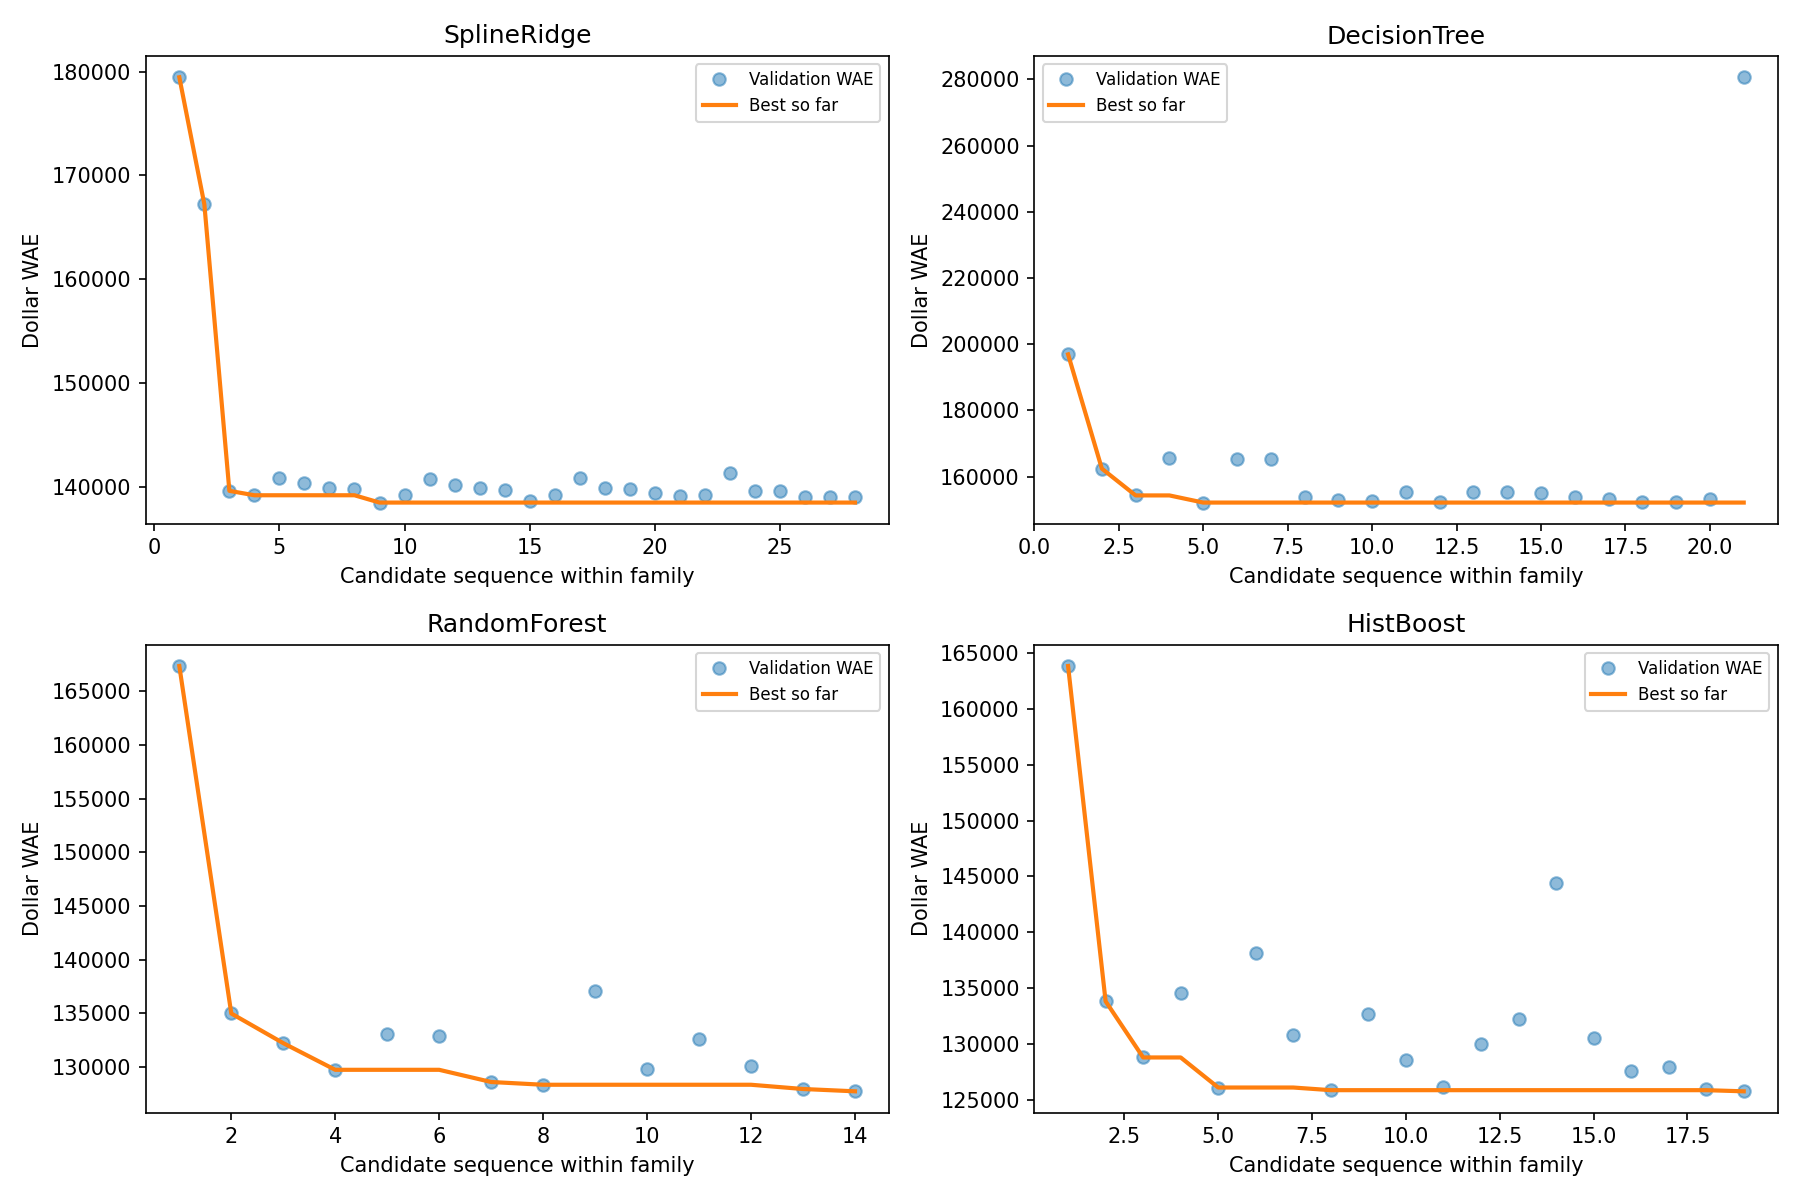

In [16]:
def train_select(train, valid, sets, out):
    """先比较特征，再分别调参；每个模型族选一名冠军，再统一比较。"""
    from sklearn.base import clone
    from sklearn.model_selection import ParameterGrid, ParameterSampler
    from collections import OrderedDict
    ytrain = train.sale_price.to_numpy()
    yvalid = valid.sale_price.to_numpy()
    rows, specs, seen = [], [], set()
    # 同一固定训练集可以复用相同预处理的矩阵。缓存不接触测试集，且不拟合验证数据。
    # 最多缓存两个方案，避免不断保存样条矩阵占满内存。
    cache = OrderedDict()

    def transformed_data(spec):
        nums, cats = sets[spec['feature_set']]
        opts = {k: spec['params'].get(k, v) for k, v in
                [('n_knots', 4), ('degree', 3), ('knots', 'uniform')]} if spec['family'] == 'SplineRidge' else {}
        key = (spec['feature_set'], json.dumps(opts, sort_keys=True))
        if key in cache:
            cache.move_to_end(key)
            return cache[key]
        pre = preprocessing(nums, cats, spec['family'] == 'SplineRidge', **opts)
        # 关键：fit_transform 仅用于 2023；2024 只调用 transform。
        xt = pre.fit_transform(train[nums + cats])
        xv = pre.transform(valid[nums + cats])
        cache[key] = (xt, xv)
        if len(cache) > 2:
            cache.popitem(last=False)
        return xt, xv

    def evaluate(family, params, feature_set='C_all_archived', target='log', phase='systematic_tuning'):
        signature = (family, feature_set, target, json.dumps(params, sort_keys=True))
        if signature in seen:
            return None
        seen.add(signature)
        spec = {'candidate_id': f'M{len(specs)+1:03}', 'family': family, 'feature_set': feature_set,
                'params': params.copy(), 'target': target, 'phase': phase}
        specs.append(spec)
        dump_json(out/'experiment_registry.json', {'main_weights': MAIN_WEIGHTS, 'specs': specs})
        start = time.time()
        xt, xv = transformed_data(spec)
        full = model_for(spec, sets)
        pipe = full.regressor if target == 'log' else full
        reg = clone(pipe.named_steps['regressor'])
        # 直接在同一个训练期预处理矩阵拟合，等价于 Pipeline.fit；不是提前填补全量数据。
        reg.fit(xt, np.log1p(ytrain) if target == 'log' else ytrain)
        tp, vp = reg.predict(xt), reg.predict(xv)
        if target == 'log':
            tp, vp = np.expm1(tp), np.expm1(vp)
        tp, vp = np.maximum(tp, 0.), np.maximum(vp, 0.)
        if not (np.isfinite(tp).all() and np.isfinite(vp).all()):
            raise ValueError(f'{spec["candidate_id"]} 非有限预测，不能悄悄忽略。')
        save_validation_cache(out, spec, vp, valid)
        nums, cats = sets[feature_set]
        row = {k: v for k, v in spec.items() if k != 'params'}
        row.update(params=json.dumps(params, sort_keys=True), input_features=len(nums + cats),
                   fit_seconds=time.time()-start, train_MAE=mean_absolute_error(ytrain, tp),
                   train_WAE_main=wae(ytrain, tp), **metrics(yvalid, vp))
        if family == 'DecisionTree':
            row.update(fitted_leaves=reg.get_n_leaves(), fitted_depth=reg.get_depth())
        rows.append(row)
        pd.DataFrame(rows).to_csv(out/'validation_results.csv', index=False)
        print(f"{spec['candidate_id']} {family} {phase}: WAE={row['WAE_main']:,.0f}; {params}", flush=True)
        return spec

    baselines = {'baseline_median': DummyRegressor(strategy='median'),
                 'baseline_weighted_quantile': DummyRegressor(strategy='quantile', quantile=1/3)}
    for name, base in baselines.items():
        base.fit(train[['valuation_trend']], ytrain)
        pred = predict_price(base, valid[['valuation_trend']])
        rows.append({'candidate_id': name, 'family': name, 'feature_set': 'constant', 'params': '{}',
                     'target': 'raw', 'phase': 'baseline', **metrics(yvalid, pred)})

    # 搜索计划在任何新增调参结果出现前保存。没有随机时间截止，候选数可复现。
    plan = {
        'primary_objective': 'validation main WAE, over=2 under=1',
        'split': '2023 train / 2024 validation; property-disjoint; no 2025 input',
        'feature_experiment': 'seven families x A/B/C at original default parameters',
        'tuning_features': 'C_all_archived; previous A/B/C candidates remain eligible',
        'SplineRidge': {'n_knots': [3, 5, 7], 'degree': [1, 3], 'alpha': [.1, 1., 10., 100.]},
        'DecisionTree_structure': {'max_depth': [5, 8, 12, None], 'min_samples_leaf': [20, 100]},
        'DecisionTree_pruning': 'training-only path, at most eight positive quantile-spaced ccp_alpha values, min_samples_leaf=20',
        'RandomForest_randomized': {'draws': 8, 'seed': SEED, 'n_estimators': [60],
            'max_depth': [10, 14, 20, None], 'min_samples_leaf': [5, 10, 20, 50], 'max_features': [.3, .7, 1.]},
        'RandomForest_tree_count_refinement': [120, 240],
        'HistBoost_randomized': {'draws': 10, 'seed': SEED,
            'learning_rate': [.03, .08, .15], 'max_iter': [120, 240, 400],
            'max_leaf_nodes': [7, 15, 31, 63], 'min_samples_leaf': [20, 40, 100], 'l2_regularization': [.1, 10., 100.]},
        'HistBoost_iteration_refinement': [120, 240, 400, 600],
        'selection': 'minimum validation WAE per family; exact ties use candidate ID; minimum champion WAE overall; no 0.5% tolerance',
        'limits': 'finite budget; training uses log squared error except raw-target comparator; search objective uses original-dollar WAE',
        'course_mapping': {
            '07': 'regularization strength selection; course uses classification, here regression',
            '08': 'vary spline knots/degree and regularization; Ridge spline basis is not the same as pyGAM smoothing penalty',
            '09': 'training-only cost complexity pruning; randomized forest parameter search in place of Optuna',
            '10': 'boosting complexity/learning-rate/iterations search; sklearn HistBoost is not LightGBM'},
    }
    dump_json(out/'predeclared_search_plan.json', plan)

    # 保留旧版的 32 个配置作为特征实验和原始调参起点，避免扩大搜索后丢失原有好方案。
    for initial in specs_for(sets):
        evaluate(initial['family'], initial['params'], initial['feature_set'], initial['target'], initial['phase'])

    # 课件 08：节点数和阶数决定曲线灵活度；课件 07：alpha 控制惩罚。
    # 固定 knots='uniform' 与课件示例一致；不声称等同于 pyGAM 的曲率惩罚。
    for params in ParameterGrid(plan['SplineRidge']):
        evaluate('SplineRidge', {**params, 'knots': 'uniform'}, phase='spline_grid')

    # 课件 09：除了预剪枝，还沿训练集生成的 ccp_alpha 路径进行后剪枝。
    for params in ParameterGrid(plan['DecisionTree_structure']):
        evaluate('DecisionTree', params, phase='tree_structure_grid')
    dummy_spec = {'family': 'DecisionTree', 'feature_set': 'C_all_archived', 'params': {}, 'target': 'log'}
    xt, _ = transformed_data(dummy_spec)
    path = DecisionTreeRegressor(min_samples_leaf=20, random_state=SEED).cost_complexity_pruning_path(xt, np.log1p(ytrain))
    positive = np.unique(path.ccp_alphas[path.ccp_alphas > 0])
    indices = np.unique(np.round(np.linspace(0, len(positive)-1, min(8, len(positive)))).astype(int)) if len(positive) else []
    selected_alphas = positive[indices] if len(positive) else []
    dump_json(out/'training_pruning_path.json', {'source': '2023 training only, log target',
        'path_size': len(path.ccp_alphas), 'selected_alphas': list(selected_alphas), 'min_samples_leaf': 20})
    evaluate('DecisionTree', {'min_samples_leaf': 20, 'ccp_alpha': 0.}, phase='tree_pruning_grid')
    for alpha in selected_alphas:
        evaluate('DecisionTree', {'min_samples_leaf': 20, 'ccp_alpha': float(alpha)}, phase='tree_pruning_grid')

    # 课件 09 用 Optuna 搜索森林；这里用固定种子的 ParameterSampler，减少额外依赖。
    rf_space = {k: v for k, v in plan['RandomForest_randomized'].items() if k not in ['draws', 'seed']}
    for params in ParameterSampler(rf_space, n_iter=8, random_state=SEED):
        evaluate('RandomForest', params, phase='forest_random_search')
    rf_best_row = pd.DataFrame(rows).query("family == 'RandomForest'").sort_values(['WAE_main','candidate_id']).iloc[0]
    rf_best = json.loads(rf_best_row.params)
    for trees in plan['RandomForest_tree_count_refinement']:
        evaluate('RandomForest', {**rf_best, 'n_estimators': trees},
                 feature_set=rf_best_row.feature_set, target=rf_best_row.target, phase='forest_tree_refinement')

    # 课件 10：联合改变树复杂度、惩罚、学习率和轮数。
    # max_leaf_nodes 对应类似的叶数概念，但不直接复制 LightGBM 不兼容的参数。
    hb_space = {k: v for k, v in plan['HistBoost_randomized'].items() if k not in ['draws', 'seed']}
    for params in ParameterSampler(hb_space, n_iter=10, random_state=SEED):
        evaluate('HistBoost', params, phase='boost_random_search')
    hb_best_row = pd.DataFrame(rows).query("family == 'HistBoost'").sort_values(['WAE_main','candidate_id']).iloc[0]
    hb_best = json.loads(hb_best_row.params)
    for rounds in plan['HistBoost_iteration_refinement']:
        evaluate('HistBoost', {**hb_best, 'max_iter': rounds},
                 feature_set=hb_best_row.feature_set, target=hb_best_row.target, phase='boost_iteration_refinement')

    table = pd.DataFrame(rows)
    candidates = table.loc[table.phase.ne('baseline')].copy()
    # 先给每个模型族找出已搜索候选中的最佳版本，每个族只占最终比较表的一行。
    champions = candidates.sort_values(['WAE_main','candidate_id']).drop_duplicates('family').copy()
    champions.sort_values('WAE_main').to_csv(out/'best_model_per_family.csv', index=False)
    table.sort_values('WAE_main').to_csv(out/'model_comparison_all_candidates.csv', index=False)
    comparison = pd.concat([table.loc[table.phase.eq('baseline')], champions], ignore_index=True).sort_values('WAE_main')
    comparison.to_csv(out/'model_comparison_final.csv', index=False)
    table.loc[~table.phase.isin(['baseline','feature_comparison'])].to_csv(out/'tuning_log.csv', index=False)
    table.loc[table.phase.eq('feature_comparison')].to_csv(out/'feature_comparison_controlled.csv', index=False)
    summaries = []
    for family in champions.family:
        before = candidates.loc[candidates.family.eq(family) & candidates.phase.isin(['feature_comparison','tuning','target_experiment'])].sort_values('WAE_main').iloc[0]
        after = champions.loc[champions.family.eq(family)].iloc[0]
        summaries.append({'family': family, 'before_best_WAE': before.WAE_main, 'after_best_WAE': after.WAE_main,
            'improvement_pct': 100*(1-after.WAE_main/before.WAE_main), 'before_params': before.params,
            'after_params': after.params, 'tested_configurations': int(candidates.family.eq(family).sum())})
    pd.DataFrame(summaries).to_csv(out/'tuning_improvement_by_family.csv', index=False)

    # 不再使用原先 0.5% 容差与人为模型族复杂度排序。
    selected = champions.sort_values(['WAE_main','candidate_id']).iloc[0]
    spec = next(s for s in specs if s['candidate_id'] == selected.candidate_id)
    nums, cats = sets[spec['feature_set']]
    cols = nums + cats
    cache.clear()
    best_model = model_for(spec, sets).fit(train[cols], ytrain)
    # 核对缓存加速的实现与最终完整 Pipeline 的验证预测一致。
    check_pred = predict_price(best_model, valid[cols])
    assert np.isclose(wae(yvalid, check_pred), selected.WAE_main, rtol=1e-6)

    sample = valid.sample(min(1200, len(valid)), random_state=SEED)
    def neg_wae(estimator, x, y): return -wae(y, predict_price(estimator, x))
    imp = permutation_importance(best_model, sample[cols], sample.sale_price,
                                scoring=neg_wae, n_repeats=2, random_state=SEED, n_jobs=1)
    pd.DataFrame({'feature': cols, 'increase_in_WAE_when_permuted': imp.importances_mean,
                  'repeat_std': imp.importances_std}).sort_values('increase_in_WAE_when_permuted', ascending=False).to_csv(
                      out/'validation_permutation_importance.csv', index=False)
    if spec['family'] in ['OLS','Ridge','Lasso','SplineRidge']:
        pipe = best_model.regressor_ if spec['target'] == 'log' else best_model
        pd.DataFrame({'transformed_feature': pipe['preprocess'].get_feature_names_out(),
                      'coefficient': pipe['regressor'].coef_}).to_csv(out/'linear_coefficients.csv', index=False)
    locked = {'selected_spec': spec, 'validation_metrics': selected.to_dict(), 'main_weights': MAIN_WEIGHTS,
        'selection_rule': 'minimum validation main WAE among one champion per family',
        'n_candidates': len(candidates), 'n_families': len(champions), 'test_used_for_selection': False,
        'refit': 'same features/parameters, train+validation only', 'predictions_fixed_across_scenarios': True,
        'test_history_note': '2025 results appeared in an earlier notebook. This revision uses no test scores for tuning; the set is not a newly unseen holdout.'}
    dump_json(out/'model_lock.json', locked)
    # 调参轨迹：只展示验证信息，不展示测试候选成绩。
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for ax, family in zip(axes.ravel(), ['SplineRidge','DecisionTree','RandomForest','HistBoost']):
        sub = candidates.loc[candidates.family.eq(family)].copy()
        ax.plot(range(1,len(sub)+1), sub.WAE_main, 'o', alpha=.5, label='Validation WAE')
        ax.plot(range(1,len(sub)+1), sub.WAE_main.cummin(), lw=2, label='Best so far')
        ax.set(title=family, xlabel='Candidate sequence within family', ylabel='Dollar WAE')
        ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(out/'tuning_progress.png', dpi=150); plt.close(fig)
    champion_display = champions[['family','candidate_id','feature_set','WAE_main','MSE','R2','MAE','params']].rename(columns={'R2':'R²'})
    print('\nBest validation results by model family:\n', champion_display.sort_values('WAE_main').to_string(index=False))
    print('\n调参前后：\n',pd.DataFrame(summaries)[['family','tested_configurations','before_best_WAE','after_best_WAE','improvement_pct']].round(3).to_string(index=False))
    return spec, best_model, baselines

# 第一步：分别选出各模型族最佳版本；第二步：再比较模型族冠军。
spec, selected_train_model, baseline_models = train_select(train,valid,sets,OUT)
comparison = pd.read_csv(OUT/'model_comparison_final.csv')
all_candidates = pd.read_csv(OUT/'validation_results.csv')
print(comparison[['candidate_id','family','feature_set','target','WAE_main','MSE','R2','MAE']].rename(columns={'R2':'R²'}).to_string(index=False))
print('最终冻结设置：', json.dumps(spec,ensure_ascii=False,indent=2))
show_image(OUT/'tuning_progress.png')


### 7.1 各模型最优配置与实际价格走势；不同参数的预测曲线

> 本节保留原A/B/C实验的各族冠军图；加入D后的最终统一排名见7.3，最终冠军的专门走势与业务解释见8.1–8.2。

**第一组：按真实时间比较。** 七个模型族各自验证集最优配置，都在 2023 训练、预测同一批 2024 验证房屋。黑线是当月实际成交均价，红线是同一批成交房屋的预测均价。不是逐笔交易随意连线，也不是控制房屋质量后的市场价格指数。月均值会掩盖个体误差，应结合 MAE/WAE 和残差评价。

**第二组：模仿参考图的多参数曲线叠加。** 用同一批验证房屋按建筑面积分为 20 个分位箱，在相同箱中计算实际均价与各配置预测均价。灰点是实际价格抽样（显示时排除最高 1%，分箱曲线不删高价）；黑虚线为实际分箱均价，细彩线为不同的已测试参数配置，粗红线为已选最优配置。

这些曲线是**多变量模型在真实房屋组合上的分组预测**，不是单变量拟合函数、PDP 或面积的因果影响。无需人为制造不可能的房屋组合，也不会把其他属性差异误称为面积的净效应。

- Ridge/Lasso：比较 alpha；样条：固定冠军的阶数和 alpha，比较节点数。
- 随机森林：固定冠军结构，比较 60/120/240 棵树；Histogram Boosting：固定冠军结构，比较 120/240/400/600 轮。
- 决策树：代表配置同时改变深度和叶样本数；不能将图读成只改变深度的受控实验。
- OLS 没有这类超参数，只有一条模型曲线。其余每图选 3–4 个已测试代表配置；全部 95 个候选仍保留在实验日志和原调参轨迹图中。

**最优标准仍是逐笔验证主 WAE。** 不根据图中月均值／分箱均值的贴合程度重新选优。“不同参数”是分别训练不同配置，不是一次训练中自动逐步改参。新增绘图不改超参数、模型冠军或 2025 测试预测。

绘图会优先读取训练阶段保存的验证预测；若使用之前未保存缓存的运行目录，只重建图中需要的已评估配置，并断言其 WAE 与实验记录一致。

绘图预测已核对： M015 OLS OLS (no tuning)
绘图预测已核对： M016 Ridge alpha=10
绘图预测已核对： M017 Lasso alpha=0.001
绘图预测已核对： M019 DecisionTree depth=8, leaf=100
绘图预测已核对： M022 Ridge alpha=0.1
绘图预测已核对： M023 Ridge alpha=100
绘图预测已核对： M024 Lasso alpha=0.0001
绘图预测已核对： M025 Lasso alpha=0.01
绘图预测已核对： M027 DecisionTree depth=5, leaf=200
绘图预测已核对： M028 DecisionTree depth=12, leaf=30
绘图预测已核对： M036 SplineRidge knots=3, degree=3, a=0.1
绘图预测已核对： M037 SplineRidge knots=5, degree=3, a=0.1
绘图预测已核对： M038 SplineRidge knots=7, degree=3, a=0.1
绘图预测已核对： M062 DecisionTree depth=None, leaf=20
绘图预测已核对： M076 RandomForest trees=60
绘图预测已核对： M081 RandomForest trees=120
绘图预测已核对： M082 RandomForest trees=240
绘图预测已核对： M084 HistBoost rounds=400
绘图预测已核对： M093 HistBoost rounds=120
绘图预测已核对： M094 HistBoost rounds=240
绘图预测已核对： M095 HistBoost rounds=600
candidate_id       family                                                                                                             params      WAE_main
        M015          OLS                

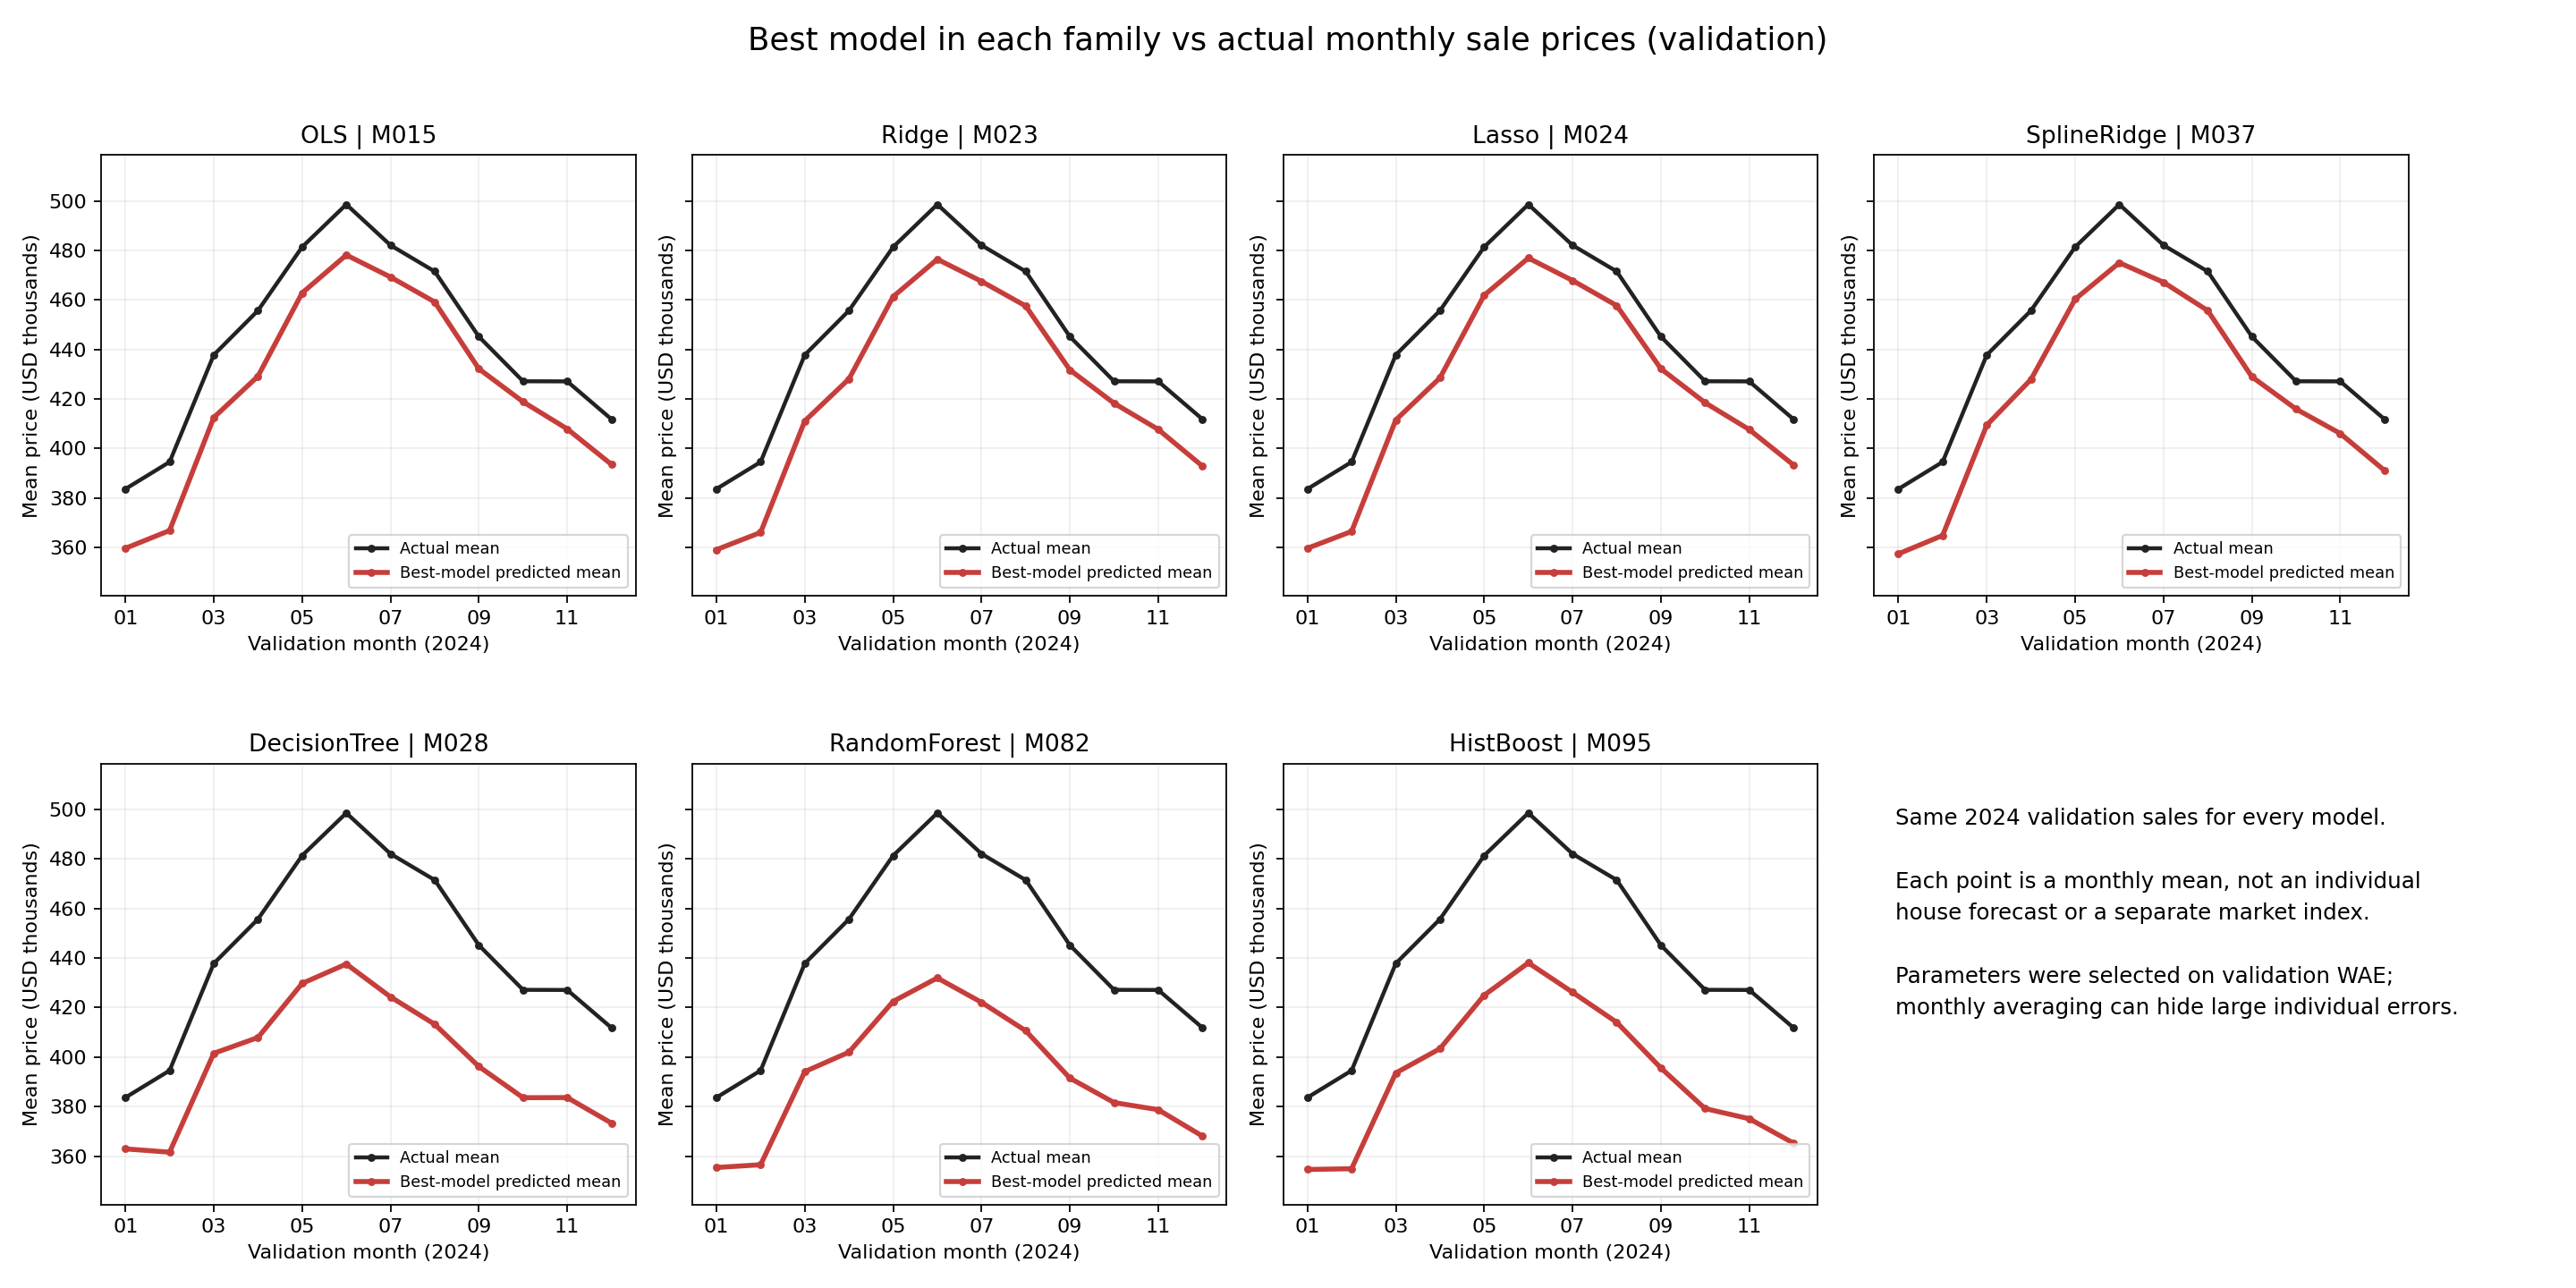

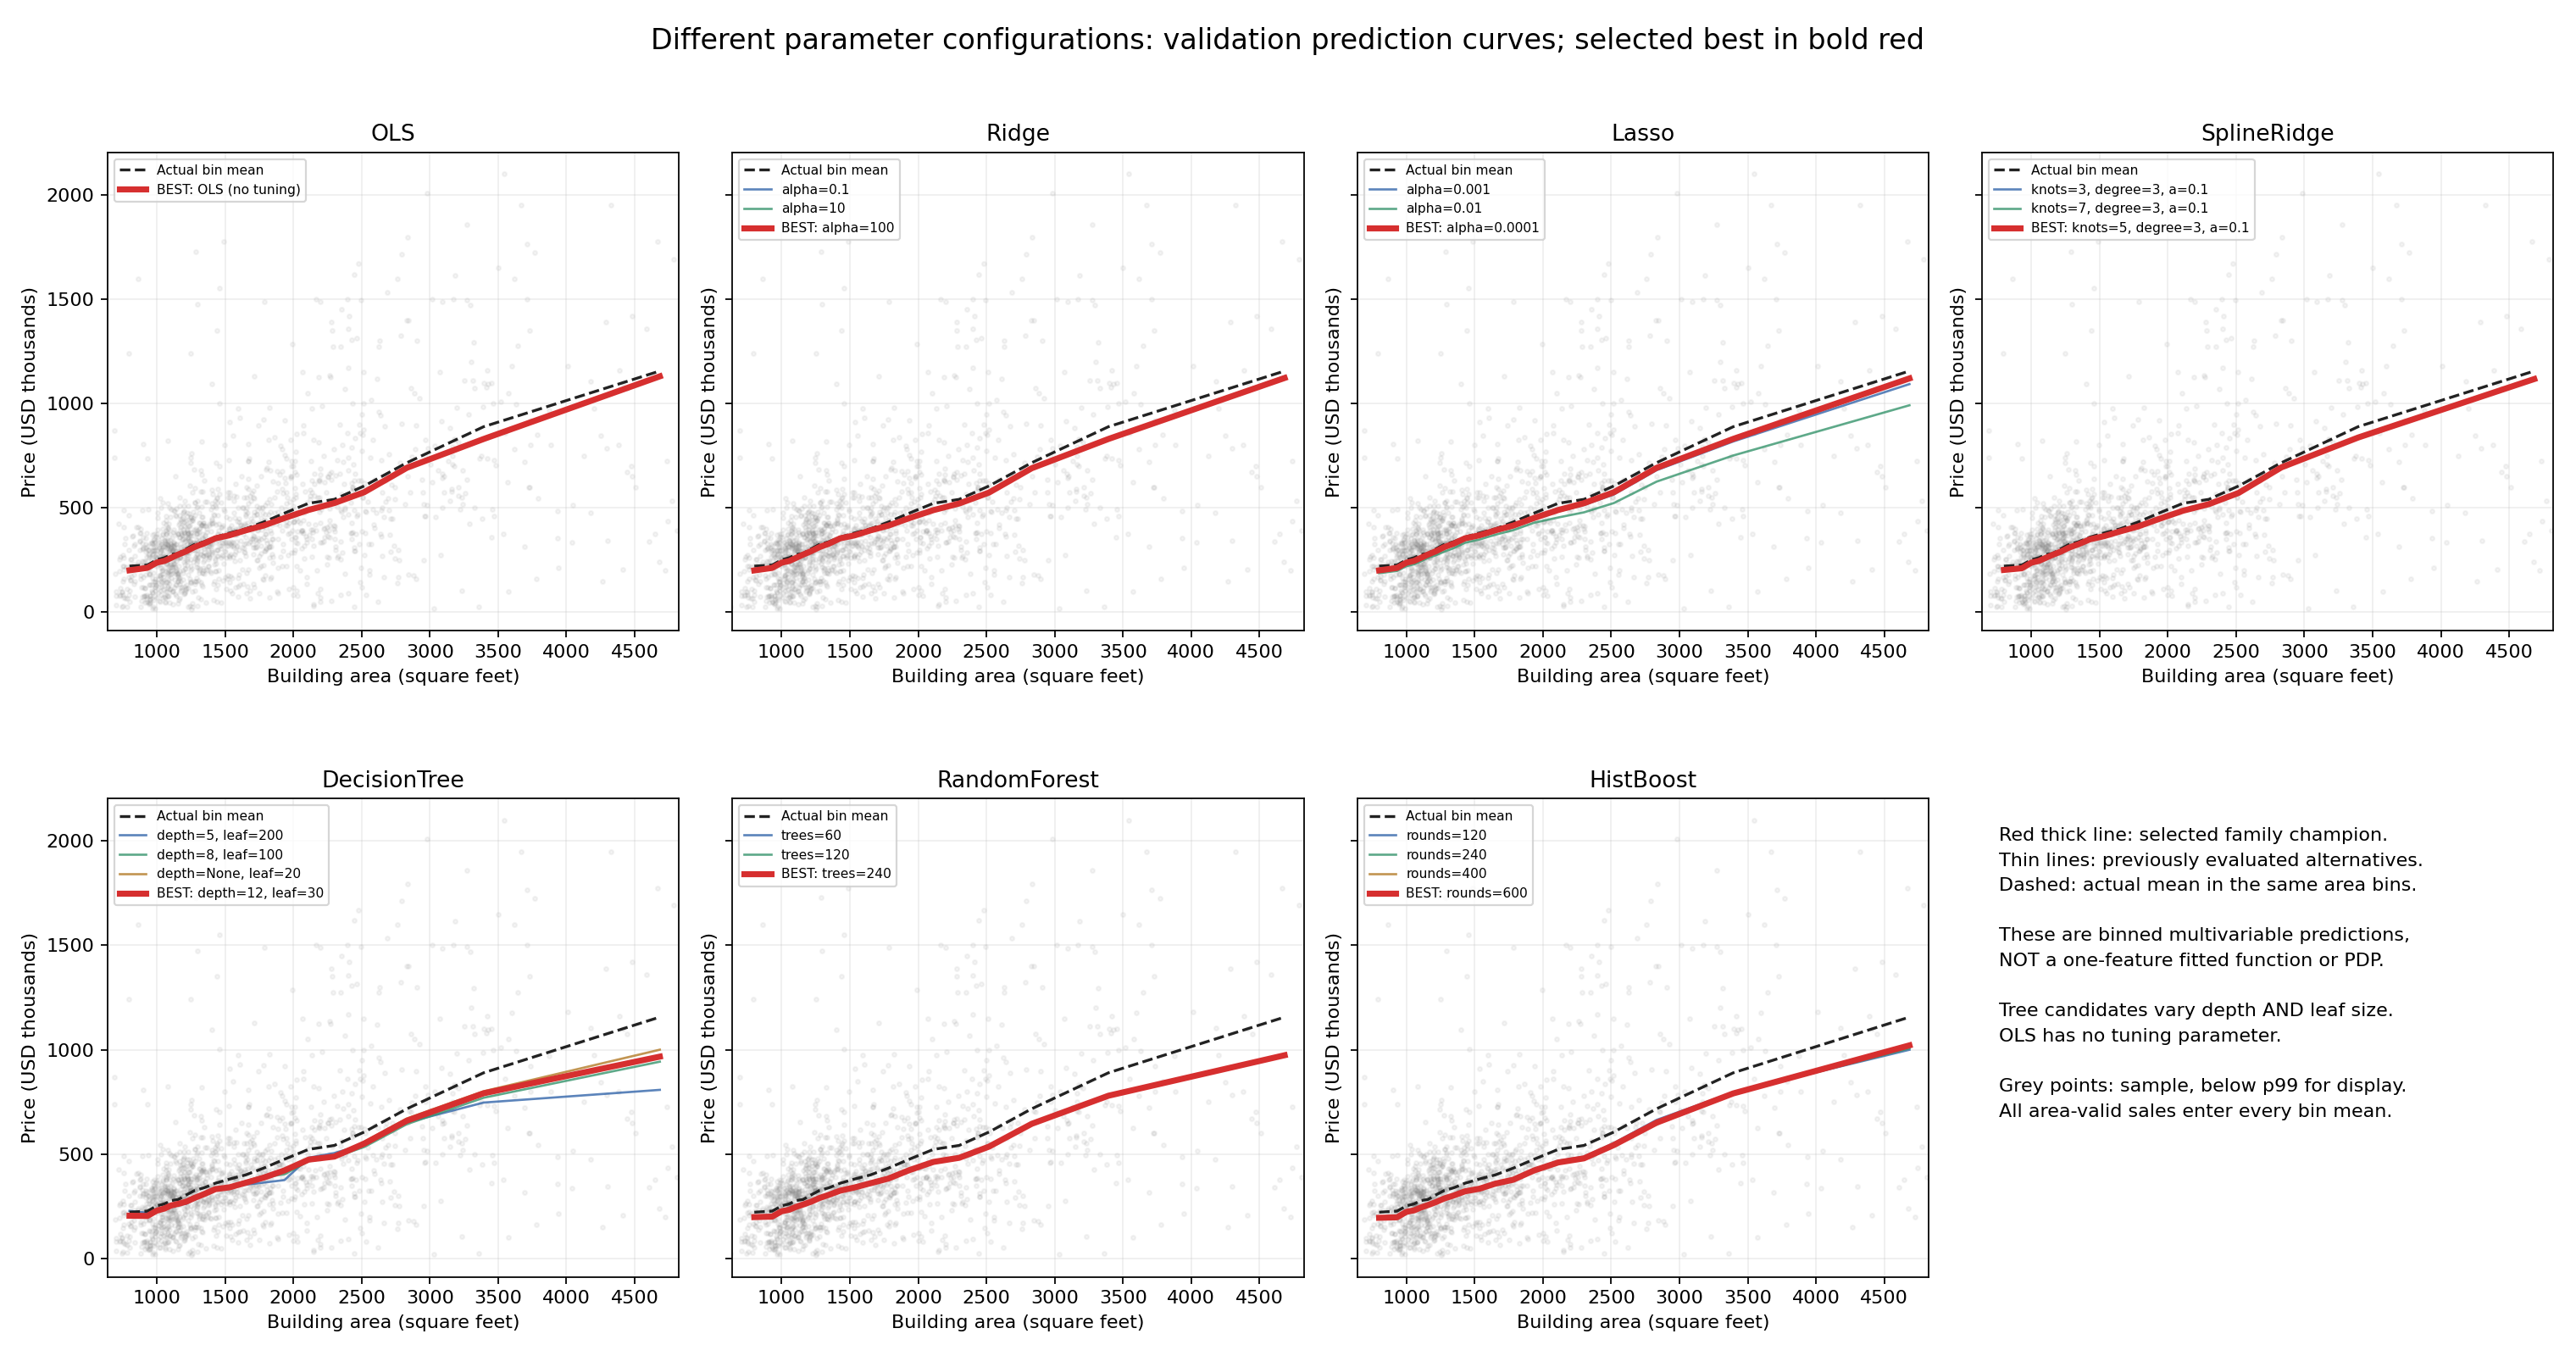

In [22]:
# 绘制与核对：所有模型都使用同一批验证交易，最优曲线用粗红线显示。
monthly_model_comparison, plotted_configurations = plot_best_models_and_parameter_curves(train,valid,sets,OUT)
print(plotted_configurations[['candidate_id','family','params','WAE_main']].to_string(index=False))
show_image(OUT/'best_models_actual_monthly.png')
show_image(OUT/'parameter_prediction_curves.png')

### 7.2 Fixed-Parameter Feature Sensitivity: C vs D Across Seven Model Families

D was defined using 2023 data in Section 5.1. Each of the seven model families uses the same parameters as its original C champion, fits on the full 2023 training set, and predicts the same 2024 validation transactions. C results are reused from the original experiment log; D is fitted once more. The comparison reports feature count, WAE, MSE, R² and MAE; a negative WAE change means D has lower WAE.

This is a **fixed-parameter feature-sensitivity experiment**: D is not retuned, so this is not a fully optimized head-to-head comparison and the parameters selected on C may favor C. Section 7.3 ranks the seven additional D configurations together with the original 95 configurations; the selected champion did not change in that experiment. Any future formal selection involving D should use a predeclared, equal search budget for C and D and keep all choices within development data. The previously viewed 2025 set cannot become a new blind holdout.


HistBoost : C WAE= 125750.58 ; D WAE= 127063.47
RandomForest : C WAE= 127759.42 ; D WAE= 128770.8
SplineRidge : C WAE= 138460.79 ; D WAE= 163555.74
Lasso : C WAE= 140693.52 ; D WAE= 163488.48
Ridge : C WAE= 140981.35 ; D WAE= 164337.62
OLS : C WAE= 141200.8 ; D WAE= 163265.21
DecisionTree : C WAE= 152131.2 ; D WAE= 149806.4

C/D对比（WAE变化为负表示D更好）：
       family  C_features  D_features     C_WAE     D_WAE  WAE_change_pct
   HistBoost         105          14 125750.58 127063.47            1.04
RandomForest         105          14 127759.42 128770.80            0.79
 SplineRidge         105          14 138460.79 163555.74           18.12
       Lasso         105          14 140693.52 163488.48           16.20
       Ridge         105          14 140981.35 164337.62           16.57
         OLS         105          14 141200.80 163265.21           15.63
DecisionTree         105          14 152131.20 149806.40           -1.53

说明：这是固定已有C冠军参数的特征敏感性实验。D未重新调参，由第7.3节与原95配置统一比较；未新增2025评估。
图表已生成： /

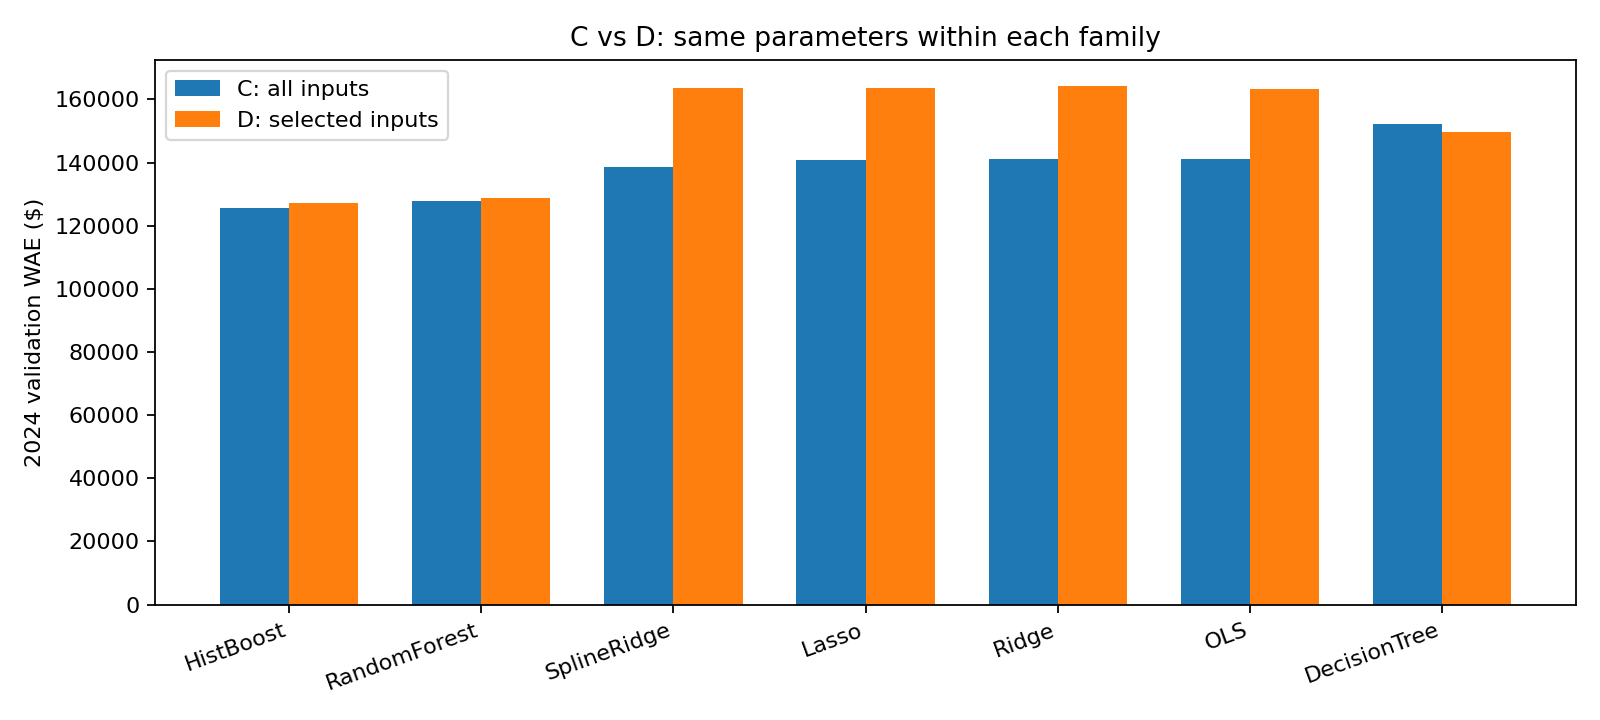

In [24]:
def compare_c_d_fixed_parameters(train,valid,sets_with_D,out):
    """Compare C and D with identical parameters within each family; D is not retuned."""
    champions=pd.read_csv(out/'best_model_per_family.csv')
    assert champions.feature_set.eq('C_all_archived').all()
    records=[]
    for _,row in champions.iterrows():
        params=json.loads(row.params)
        spec_d=dict(family=row.family,feature_set='D_selected',params=params,target=row.target)
        start=time.time()
        dn,dc=sets_with_D['D_selected']
        model_d=model_for(spec_d,sets_with_D).fit(train[dn+dc],train.sale_price)
        pred_d=predict_price(model_d,valid[dn+dc])
        result=metrics(valid.sale_price.to_numpy(),pred_d)
        records.append(dict(family=row.family,C_candidate_id=row.candidate_id,
            C_features=int(row.input_features),D_features=len(dn+dc),
            C_WAE=row.WAE_main,D_WAE=result['WAE_main'],C_MAE=row.MAE,D_MAE=result['MAE'],
            C_MSE=row.MSE,D_MSE=result['MSE'],C_R2=row.R2,D_R2=result['R2'],
            WAE_change_pct=100*(result['WAE_main']/row.WAE_main-1),
            params=row.params,target=row.target,D_fit_seconds=time.time()-start))
        print(row.family,': C WAE=',round(row.WAE_main,2),'; D WAE=',round(result['WAE_main'],2),flush=True)
    table=pd.DataFrame(records)
    table.to_csv(out/'C_vs_D_fixed_parameter_comparison.csv',index=False)
    fig,ax=plt.subplots(figsize=(10,4.5))
    x=np.arange(len(table));ax.bar(x-.18,table.C_WAE,width=.36,label='C: all inputs')
    ax.bar(x+.18,table.D_WAE,width=.36,label='D: selected inputs')
    ax.set_xticks(x,table.family,rotation=20,ha='right')
    ax.set(ylabel='2024 validation WAE ($)',title='C vs D: same parameters within each family')
    ax.legend();fig.tight_layout();fig.savefig(out/'C_vs_D_validation_WAE.png',dpi=160);plt.close(fig)
    display_columns = ['family','C_features','D_features','C_MSE','D_MSE','C_R2','D_R2','C_MAE','D_MAE','C_WAE','D_WAE','WAE_change_pct']
    display_table = table[display_columns].rename(columns={'C_R2':'C_R²','D_R2':'D_R²'})
    print('\nC/D fixed-parameter comparison (negative WAE change means D is better):\n',display_table.round(2).to_string(index=False))
    print('\nThis is a feature-sensitivity experiment using the existing C champion parameters. D was not retuned; Section 7.3 ranks it with the original 95 configurations. No additional 2025 evaluation was performed.')
    return table

C_D_comparison=compare_c_d_fixed_parameters(train,valid,sets_with_D,OUT)
show_image(OUT/'C_vs_D_validation_WAE.png')


**本次固定参数对比的解读**：D使Decision Tree验证WAE下降1.53%；Random Forest和Histogram Boosting的WAE分别上升0.79%和1.04%；OLS、Ridge、Lasso与Spline Ridge的WAE上升约15.6%–18.1%。因此，大幅精简对树集成模型的精度损失较小，但这不是预先定义的等效结论，也不能把这个D称为所有模型通用的最优特征集。

更充分的线性表示可能需要保留更多分散的变量，且D未按各模型重新调参。此次结果支持把D作为数据收集与维护成本更低的备选方案；是否接受精度损失仍需结合成本，不能声称D全面优于C。原最终模型及2025结果保持原样。


### 7.3 所有已训练配置统一选优：原95个 + D的7个

仅用2024验证集主WAE排序，不设0.5%容差；先选各模型族冠军，再选最终冠军，结果等价于直接取所有已测试配置的最小WAE。基准不参与候选选模。D也可获选，但它只测试了沿用C参数的配置，尚未充分调参。后续第8节使用此处最终spec进行重训。2025误差不进入本步骤。


In [25]:
def select_over_all_tested_configs(all_candidates, C_D_comparison, sets, out):
    """只用2024验证WAE，把原95配置与7个D配置统一排名，不查看2025。"""
    original=all_candidates.loc[all_candidates.phase.ne('baseline')].copy()
    extra=[]
    for _,r in C_D_comparison.iterrows():
        extra.append(dict(candidate_id='D_'+r.family,family=r.family,feature_set='D_selected',
            target=r.target,params=r.params,phase='D_fixed_parameters',input_features=r.D_features,
            WAE_main=r.D_WAE,MSE=r.D_MSE,R2=r.D_R2,MAE=r.D_MAE,fit_seconds=r.D_fit_seconds))
    pool=pd.concat([original,pd.DataFrame(extra)],ignore_index=True)
    assert pool.candidate_id.is_unique
    ranked=pool.sort_values(['WAE_main','candidate_id']).reset_index(drop=True)
    ranked.insert(0,'rank',np.arange(1,len(ranked)+1))
    ranked.to_csv(out/'all_tested_model_ranking.csv',index=False)
    # 从全部配置中先选各模型族冠军，再比较七名冠军，等价于直接找全局最小WAE。
    champions=ranked.drop_duplicates('family').copy()
    best=champions.iloc[0]
    assert np.isclose(best.WAE_main,pool.WAE_main.min())
    chosen=dict(candidate_id=best.candidate_id,family=best.family,feature_set=best.feature_set,
                params=json.loads(best.params),target=best.target,phase=best.phase)
    lock=json.loads((out/'model_lock.json').read_text())
    old=lock['selected_spec']
    changed=any(old[k]!=chosen[k] for k in ['candidate_id','family','feature_set','params','target'])
    # D若胜出也能进入后续统一重训；不会因为最初在C上选模就排除D。
    sets['D_selected']=sets_with_D['D_selected']
    lock.update(selected_spec=chosen,validation_metrics=best.drop('rank').to_dict(),
        n_candidates=len(pool),n_families=len(champions),
        selection_rule='minimum 2024 main WAE across every tested original and D configuration; exact ties by candidate ID',
        D_comparison_included=True,previous_winner_changed=changed,test_used_for_selection=False)
    dump_json(out/'model_lock.json',lock)
    baselines=all_candidates.loc[all_candidates.phase.eq('baseline')]
    unified=pd.concat([baselines,pool],ignore_index=True)
    final_table=pd.concat([baselines,champions.drop(columns='rank')],ignore_index=True).sort_values('WAE_main')
    champions.to_csv(out/'best_model_per_family_unified.csv',index=False)
    final_table.to_csv(out/'model_comparison_final_unified.csv',index=False)
    print('Unified comparison: ',len(pool),' configurations across ',len(champions),' model families; no 0.5% tolerance.',sep='')
    champion_display = champions[['family','candidate_id','feature_set','input_features','WAE_main','MSE','R2','MAE']].rename(columns={'R2':'R²'})
    print('\nChampion for each model family:\n',champion_display.round(2).to_string(index=False))
    print('\nFinal selection: ',json.dumps(chosen,ensure_ascii=False,indent=2))
    print('Changed from the original champion: ',changed,'. Best means best among tested configurations only, not a global optimum.',sep='')
    return chosen,unified,final_table,ranked,changed

spec,all_candidates,comparison,unified_ranking,winner_changed=select_over_all_tested_configs(
    all_candidates,C_D_comparison,sets,OUT)
# 后续第8节使用这里的spec，在2023+2024上重训，然后只评估这一个最终模型。
if winner_changed:
    cols=sets[spec['feature_set']][0]+sets[spec['feature_set']][1]
    selected_train_model=model_for(spec,sets).fit(train[cols],train.sale_price)


统一比较配置数： 102 ；模型族数： 7 ；不设0.5%容差。

各模型族冠军：
       family   candidate_id    feature_set  input_features  WAE_main       MAE      RMSE
   HistBoost           M095 C_all_archived           105.0 125750.58 100662.68 201980.07
RandomForest           M082 C_all_archived           105.0 127759.42 102373.86 212218.63
 SplineRidge           M037 C_all_archived           105.0 138460.79  99272.28 200686.18
       Lasso           M024 C_all_archived           105.0 140693.52 100147.11 203542.59
       Ridge           M023 C_all_archived           105.0 140981.35 100462.21 204771.69
         OLS           M015 C_all_archived           105.0 141200.80 100250.22 202476.00
DecisionTree D_DecisionTree     D_selected            14.0 149806.40 116464.17 236804.60

最终选择： {
  "candidate_id": "M095",
  "family": "HistBoost",
  "feature_set": "C_all_archived",
  "params": {
    "l2_regularization": 100.0,
    "learning_rate": 0.15,
    "max_iter": 600,
    "max_leaf_nodes": 15,
    "min_samples_leaf": 40
  }

## 8. 冻结后重训与独立测试

保持特征集和超参数，在 2023+2024 重训，并重新学习这批开发数据的填补／编码。只产生一份 2025 预测，用于所有总体指标、时间／Township 分组和方向权重情景。

按物业聚类 Bootstrap 保留同一物业多笔销售的关联。它是固定模型在这份出售样本下的误差改善区间，不是单个房屋的预测区间。

                     model     n         MAE        RMSE      R2    WAE_main  mean_signed_error  median_APE  overvaluation_rate  within_20pct
            selected_model 32335  97230.7008 248910.7332  0.7450 131722.5570        -28246.9884      0.1651              0.4322        0.5776
           baseline_median 32335 249608.4901 512411.7923 -0.0808 304370.9675       -140083.5354      0.3978              0.4350        0.2798
baseline_weighted_quantile 32335 268927.5591 536189.0589 -0.1834 297849.5709       -211083.5354      0.4370              0.2905        0.2025
图表已生成： outputs_course_tuned/test_residuals.png


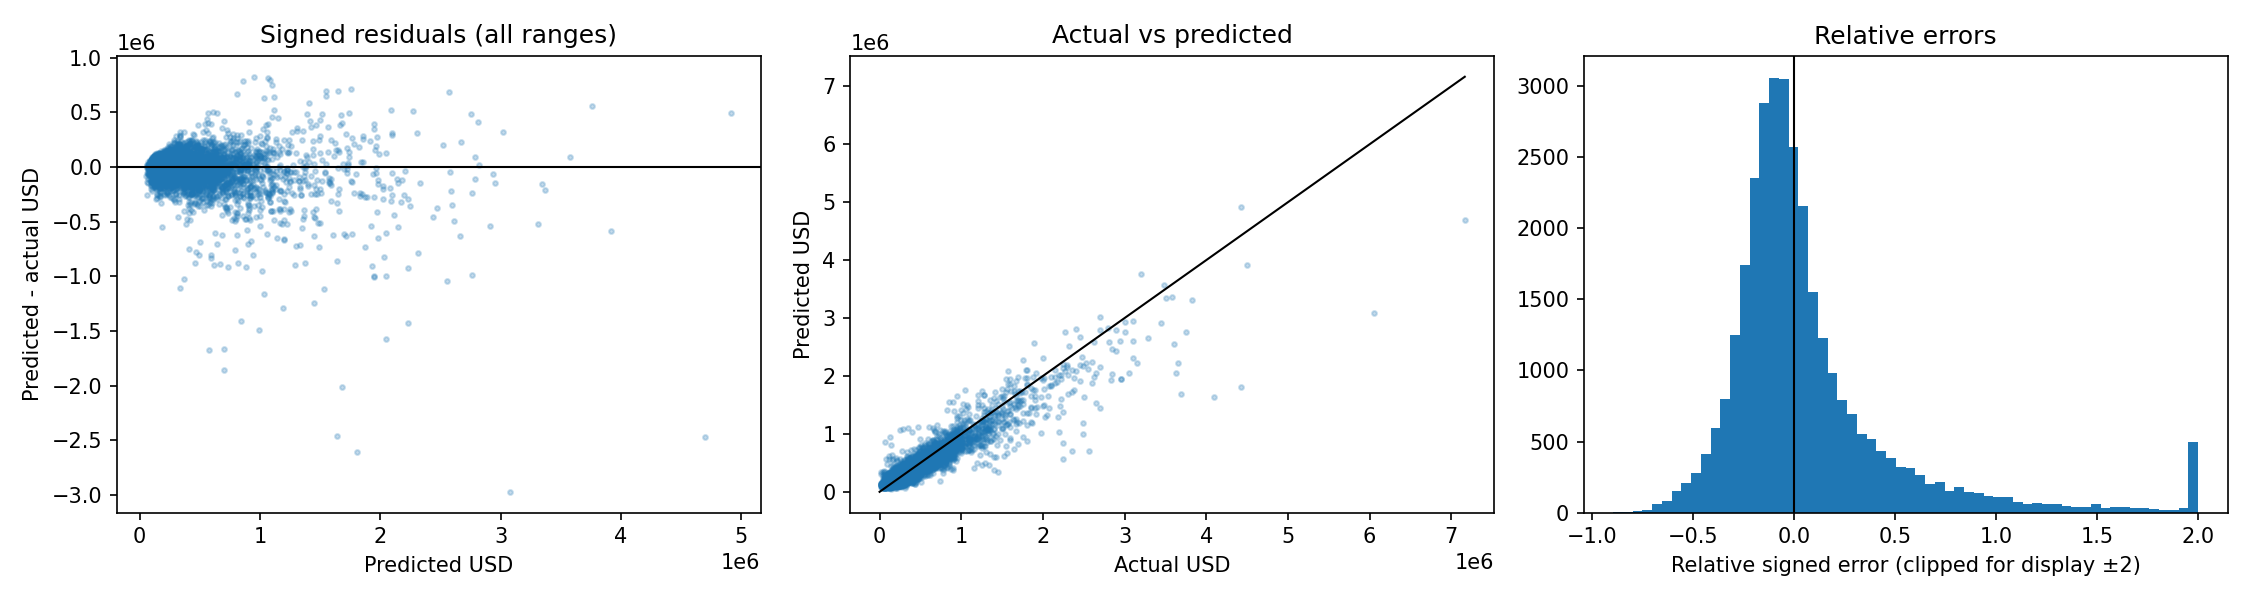

In [17]:
def grouped_performance(predictions, field):
    rows = []
    for group, sub in predictions.groupby(field, dropna=False, observed=True):
        row = {field: group, 'n_properties': sub.property_id.nunique(),
               'median_actual_price': sub.sale_price.median(), 'mean_actual_price': sub.sale_price.mean(),
               'median_building_sf': sub.char_bldg_sf.median(), 'median_age': sub.age_at_valuation.median(),
               'median_bathrooms': sub.total_bathrooms.median()}
        for col in ['final_prediction', 'baseline_prediction']:
            row.update({f'{col}_{k}': v for k, v in metrics(sub.sale_price, sub[col]).items()})
        row['improvement_main_WAE_pct'] = 100 * (1 - row['final_prediction_WAE_main'] / row['baseline_prediction_WAE_main'])
        row['small_sample_warning'] = len(sub) < 100
        rows.append(row)
    return pd.DataFrame(rows)

def clustered_ci(predictions, out):
    # Preserve dependence of repeated sales: resample whole properties, not sale rows.
    z = predictions.copy()
    z['model_loss'] = np.abs(z.final_prediction-z.sale_price) * np.where(z.final_prediction>z.sale_price, 2., 1.)
    z['baseline_loss'] = np.abs(z.baseline_prediction-z.sale_price) * np.where(z.baseline_prediction>z.sale_price, 2., 1.)
    agg = z.groupby('property_id').agg(model=('model_loss', 'sum'), baseline=('baseline_loss', 'sum'), n=('sale_price', 'size'))
    arr = agg.to_numpy(); rng = np.random.default_rng(SEED); values = []
    for _ in range(500):
        sample = arr[rng.integers(0, len(arr), size=len(arr))]
        values.append((sample[:, 1].sum()-sample[:, 0].sum()) / sample[:, 2].sum())
    dump_json(out / 'test_cluster_bootstrap.json', {'statistic': 'baseline minus model main WAE (USD)',
        'point_estimate': float((arr[:, 1].sum()-arr[:, 0].sum())/arr[:, 2].sum()),
        '95pct_interval': np.quantile(values, [.025, .975]).tolist(), 'replicates': 500,
        'caution': 'Conditional on fitted model and this sold-property sample; not uncertainty for unsold homes.'})

def final_evaluation(train, valid, test, sets, spec, baseline_models, out):
    # 3f/4: model_lock.json exists BEFORE refit or first test predictions.
    assert (out / 'model_lock.json').exists()
    development = pd.concat([train, valid], ignore_index=True)
    cols = sets[spec['feature_set']][0] + sets[spec['feature_set']][1]
    # 只有训练+验证重训；测试标签不会用于 fit 或任何预处理参数。
    model = model_for(spec, sets).fit(development[cols], development.sale_price)
    pred = predict_price(model, test[cols])
    for base in baseline_models.values(): base.fit(development[['valuation_trend']], development.sale_price)
    frame = test[['row_id', 'property_id', 'transaction_id', 'sale_date', 'sale_price',
                  'meta_township_code', 'char_bldg_sf', 'age_at_valuation', 'total_bathrooms']].copy()
    frame['final_prediction'] = pred
    frame['baseline_prediction'] = predict_price(baseline_models['baseline_median'], test[['valuation_trend']])
    frame['weighted_baseline_prediction'] = predict_price(baseline_models['baseline_weighted_quantile'], test[['valuation_trend']])
    frame['error_pred_minus_actual'] = frame.final_prediction - frame.sale_price
    frame['quarter'] = frame.sale_date.dt.to_period('Q').astype(str)
    frame['month'] = frame.sale_date.dt.to_period('M').astype(str)
    # Price strata are fixed using development quantiles, never used for selection.
    q1, q9 = development.sale_price.quantile([.1, .9])
    frame['actual_price_band'] = pd.cut(frame.sale_price, [-np.inf, q1, q9, np.inf],
                                         labels=['below_dev_p10', 'dev_p10_to_p90', 'above_dev_p90'])
    frame.to_csv(out / 'test_predictions_frozen.csv', index=False)
    dump_json(out / 'prediction_freeze.json', {'sha256': sha256(out / 'test_predictions_frozen.csv'),
                                             'fixed_across_weight_scenarios': True})
    final_metrics = []
    for label, col in [('selected_model', 'final_prediction'), ('baseline_median', 'baseline_prediction'),
                       ('baseline_weighted_quantile', 'weighted_baseline_prediction')]:
        final_metrics.append({'model': label, **metrics(frame.sale_price, frame[col])})
    pd.DataFrame(final_metrics).to_csv(out / 'test_metrics.csv', index=False)
    rows = []
    # 三种情景复用 frame 中已冻结预测，不重新训练或调整估值。
    for scenario, weights in SCENARIOS.items():
        m = wae(frame.sale_price, frame.final_prediction, weights)
        for label, col in [('baseline_median', 'baseline_prediction'), ('baseline_weighted_quantile', 'weighted_baseline_prediction')]:
            b = wae(frame.sale_price, frame[col], weights)
            rows.append({'scenario': scenario, 'over_weight': weights[0], 'under_weight': weights[1],
                         'comparator': label, 'model_WAE': m, 'baseline_WAE': b,
                         'improvement_pct': 100*(1-m/b), 'model_wins': m < b})
    pd.DataFrame(rows).to_csv(out / 'weighted_error_scenarios.csv', index=False)
    for field in ['quarter', 'month', 'meta_township_code', 'actual_price_band']:
        grouped_performance(frame, field).to_csv(out / f'test_by_{field}.csv', index=False)
    town = grouped_performance(frame, 'meta_township_code')
    town.nlargest(3, 'final_prediction_n').to_csv(out / 'test_three_largest_townships.csv', index=False)
    clustered_ci(frame, out)
    # 4a: full metrics include tail errors; figure display range does not trim evaluation.
    display = frame.sample(min(6000, len(frame)), random_state=SEED)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].scatter(display.final_prediction, display.error_pred_minus_actual, s=5, alpha=.25)
    axes[0].axhline(0, color='black', lw=1)
    axes[0].set(xlabel='Predicted USD', ylabel='Predicted - actual USD', title='Signed residuals (all ranges)')
    axes[1].scatter(display.sale_price, display.final_prediction, s=5, alpha=.25)
    high = max(display.sale_price.max(), display.final_prediction.max())
    axes[1].plot([0, high], [0, high], color='black', lw=1)
    axes[1].set(xlabel='Actual USD', ylabel='Predicted USD', title='Actual vs predicted')
    relative = frame.error_pred_minus_actual / frame.sale_price
    axes[2].hist(relative.clip(-2, 2), bins=60)
    axes[2].axvline(0, color='black', lw=1)
    axes[2].set(xlabel='Relative signed error (clipped for display ±2)', title='Relative errors')
    fig.tight_layout(); fig.savefig(out / 'test_residuals.png', dpi=150); plt.close(fig)
    joblib.dump({'model': model, 'input_columns': cols, 'spec': spec,
                 'numeric': sets[spec['feature_set']][0], 'categorical': sets[spec['feature_set']][1],
                 'archive': '2022 fixed property inputs, property year 2021 / Census 2019'}, out / 'final_model.joblib')
    return frame, pd.DataFrame(final_metrics)

assert (OUT/'model_lock.json').exists()
predictions, test_metrics = final_evaluation(train,valid,test,sets,spec,baseline_models,OUT)
print(test_metrics.round(4).to_string(index=False))
show_image(OUT/'test_residuals.png')

### 8.1 最终冠军 vs 实际价格走势

2024：只在2023拟合；2025：冻结配置后在2023+2024重训。各月预测和实际使用同一批成交交易。上图比较月均价格，下图同时展示均值偏差和逐笔MAE。2025此前已查看，本节只解释已冻结的评估结果，不据此重新选模。


         period   month    n  actual_mean  predicted_mean  mean_signed_error       MAE  WAE_main
2024 validation 2024-01 1861    383637.08       354592.10          -29044.98  90283.58 120902.88
2024 validation 2024-02 2129    394542.34       354898.04          -39644.30  96057.15 124263.58
2024 validation 2024-03 2616    437776.06       393559.11          -44216.95  98795.74 126085.13
2024 validation 2024-04 2902    455683.03       403380.25          -52302.78 101207.91 125660.47
2024 validation 2024-05 3170    481357.55       424947.38          -56410.17 105283.71 129720.48
2024 validation 2024-06 3146    498554.54       438036.07          -60518.48 108992.58 133229.62
2024 validation 2024-07 3263    482074.42       426154.16          -55920.26 104340.93 128551.27
2024 validation 2024-08 3111    471486.49       414011.31          -57475.18 108062.71 133356.47
2024 validation 2024-09 2808    445160.73       395572.59          -49588.14  98393.27 122795.83
2024 validation 2024-10 2942  

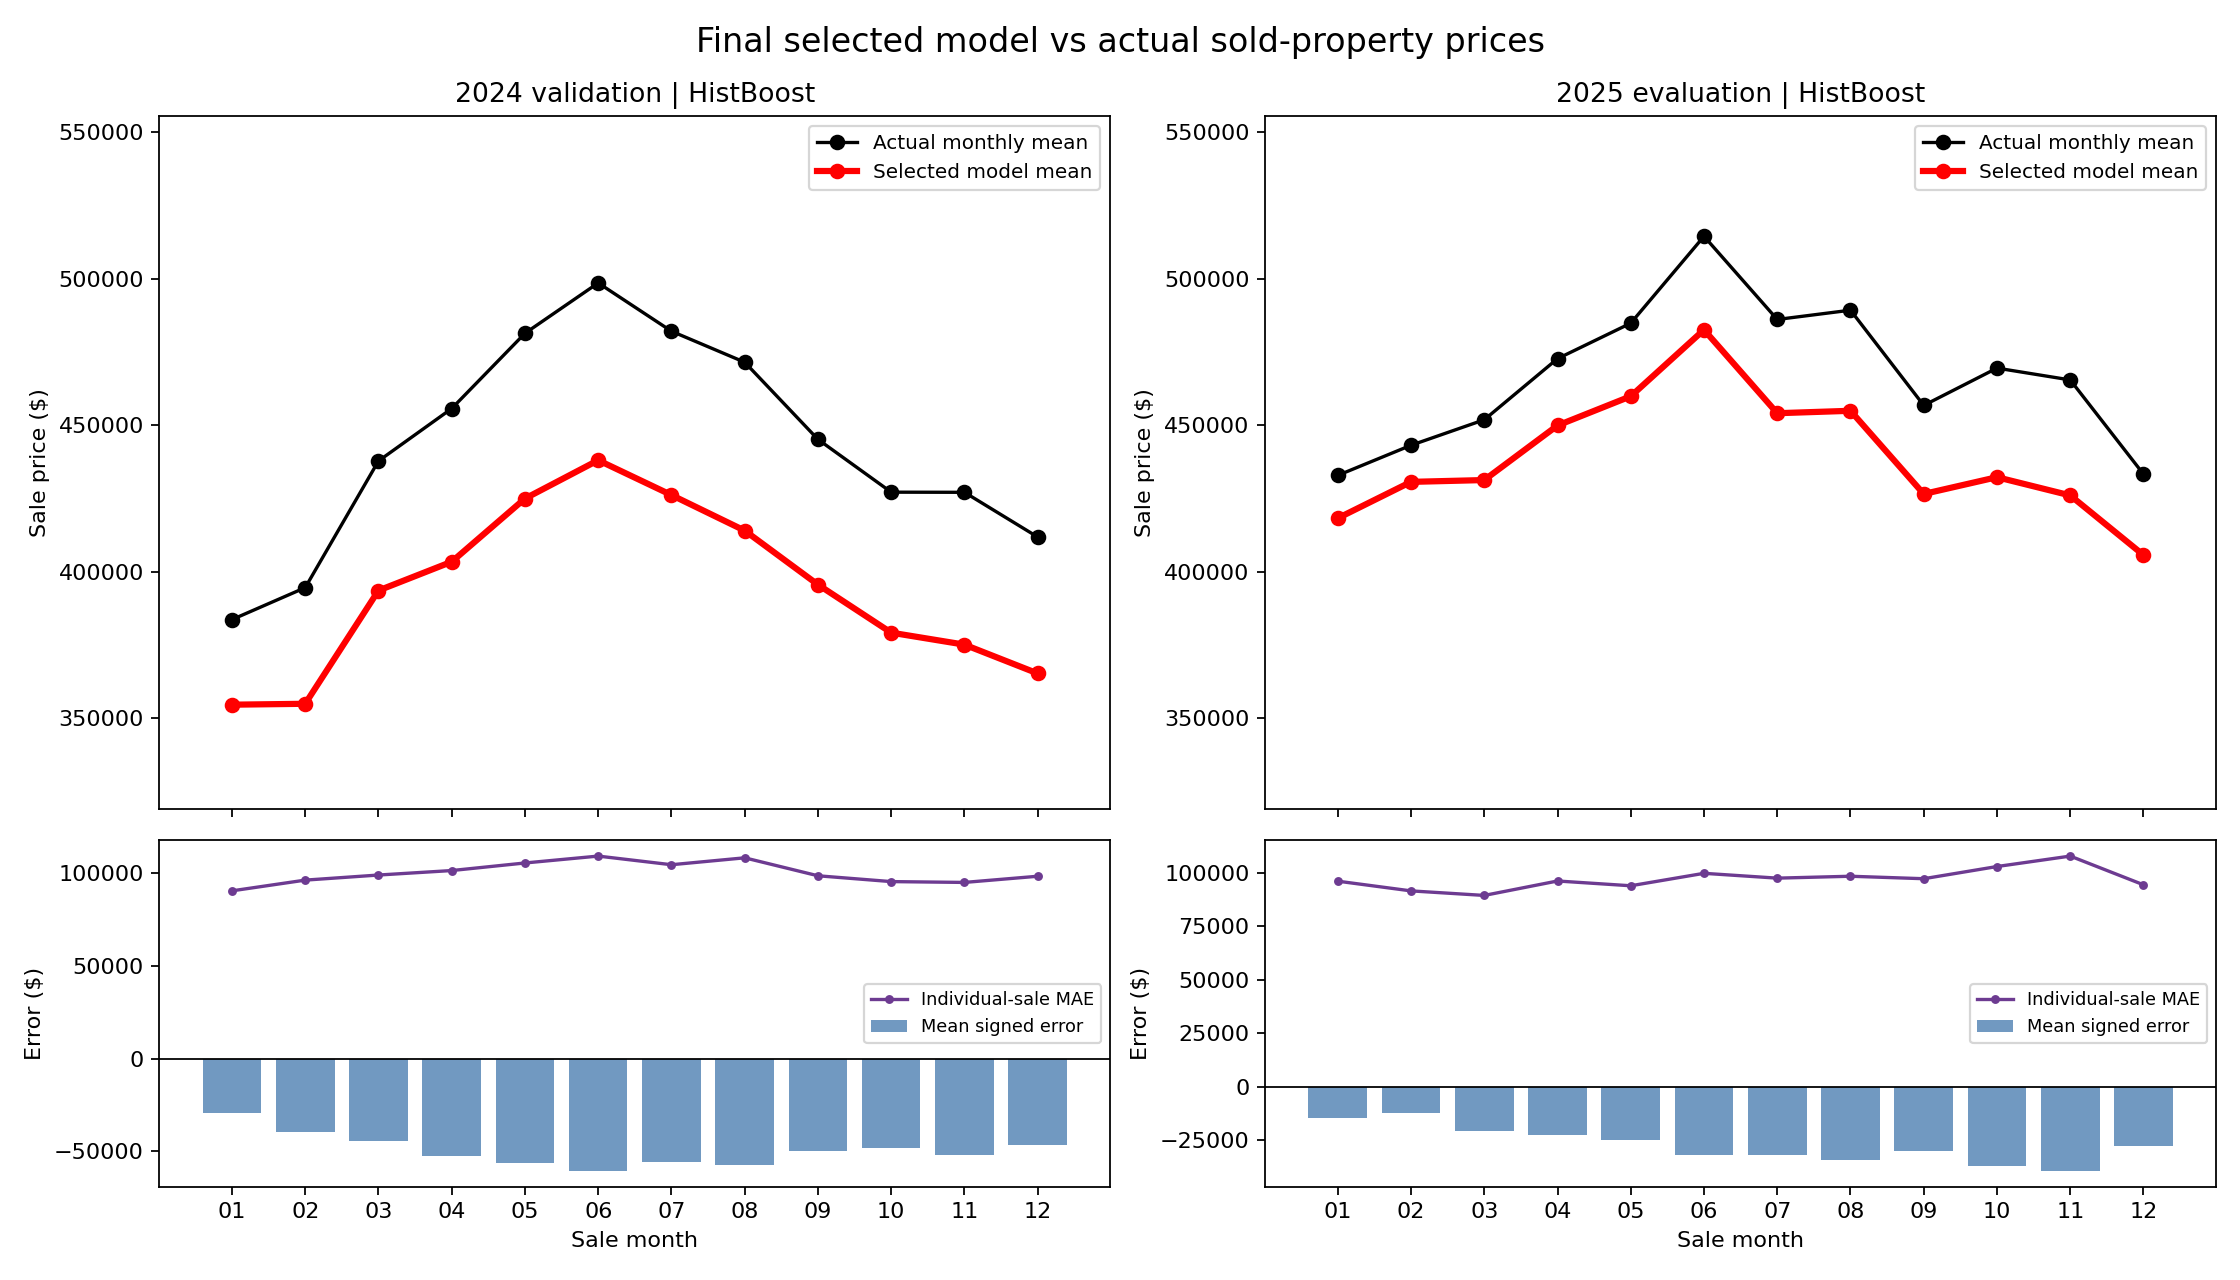

### 8.2 最终模型的实际意义：以数据证据解释用途与边界

**选中了什么，为什么选它。** 最终为 HistBoost，使用 C_all_archived，候选编号 M095。第7.3节对全部已测试配置按2024主情景WAE统一排序；主情景高估/低估权重为2/1。模型能表达非线性与交互，但这些能力本身不构成胜出的证据，实际选择依据是验证误差。该结论只适用于已测试配置，不证明所有可能参数中的全局最优。

**走势能说明什么。** 图中每个月的实际价格与预测价格来自同一批成交房屋。2024曲线使用只在2023拟合的模型；2025曲线使用冻结参数后在2023+2024重训的模型。两条曲线贴近，表示模型较好描述当月出售房屋组合的平均价位；它不是固定质量房价指数，也不是提前预测未来月份市场价格。月份之间的变化还可能来自成交房屋类型、区域、面积和高价房占比变化。2025最大绝对月均偏差出现在 2025-11，预测减实际为 $-39,419，该月逐笔MAE仍为 $107,729。下方图同时展示均值偏差和逐笔MAE，防止正负误差抵消造成过度乐观。

**单套房估值的准确度。** 在 32,335笔2025评估交易上，MAE为 $97,231，RMSE为 $248,911，R²为 0.745；57.8%的预测落在实际价格±20%内。MAE是这些交易的平均绝对偏差，不是任一房屋的误差保证或置信区间。RMSE明显高于MAE，说明部分大额误差仍影响结果；R²也不能解释为“价格预测准确率”。平均有符号误差为 $-28,247，说明该成交样本整体偏低估。

**相比简单基准的增量价值。** 主WAE为 $131,723，中位数常数基准为 $304,371，降低 56.72%；相对于1/3分位数基准降低 55.78%。这说明房屋与位置等信息在本样本上，比对所有房屋给出同一个价格更有预测价值；它不代表比专业估价师提高同样比例，也不代表节约同样比例的真实成本。

**哪些信息支撑预测。** 以下为2024验证期的模型置换重要性，不用于重新筛选D：

- `acs5_median_household_owner_occupied_value`（Median Occupied Household, Owner, Market Value）：打乱后验证WAE增加约 $60,343。
- `char_bldg_sf`（Building Square Feet）：打乱后验证WAE增加约 $60,015。
- `char_yrblt`（Year Built）：打乱后验证WAE增加约 $12,776。
- `prox_lake_michigan_dist_ft`（Lake Michigan Distance (Feet)）：打乱后验证WAE增加约 $9,773。
- `loc_latitude`（Latitude）：打乱后验证WAE增加约 $9,007。
- `char_land_sf`（Land Square Feet）：打乱后验证WAE增加约 $8,537。
- `acs5_median_income_per_capita_past_year`（Median Income, Per Capita in Past Year）：打乱后验证WAE增加约 $4,615。
- `loc_longitude`（Longitude）：打乱后验证WAE增加约 $4,399。

这些值衡量模型对变量的预测依赖，不能解读为提高某变量会让房价增加对应金额。相近位置和社区变量可能相互替代；区域ACS属性描述社区，不代表单个业主。重要性不显示影响正负方向。

**平均成绩掩盖哪些业务问题。** 按开发期价格阈值定义的低价组中，模型高估比例为 93.7%，平均有符号误差为 $74,482；高价组平均有符号误差为 $-211,107。这提示极端价位存在向中间收缩的估值表现，应安排针对低价和高价案例的人工复核；分组使用实际成交价格，只用于事后诊断，部署时不能假装提前知道该分组。

三个交易量最大的镇区也表现不同：

- 镇区代码 72：3,942笔交易，实际价格中位数 $234,000，建筑面积中位数 1,178平方英尺；MAE $71,547，中位绝对百分比误差 27.0%。
- 镇区代码 71：3,038笔交易，实际价格中位数 $468,774，建筑面积中位数 1,545平方英尺；MAE $105,422，中位绝对百分比误差 15.3%。
- 镇区代码 77：2,043笔交易，实际价格中位数 $425,000，建筑面积中位数 2,196平方英尺；MAE $147,555，中位绝对百分比误差 24.5%。

价位、面积和房屋组合差异可以帮助解释美元误差不同，但本分组对比不能识别各因素的独立或因果贡献。应同时比较相对误差，而不是仅凭美元MAE判定哪个镇区最难预测。

**高估与低估的业务取舍。** 主情景认为同额高估的惩罚是低估的两倍：例如高估$50,000计入$100,000加权损失，低估$50,000计入$50,000。这个设置可表达估值过高引发负担或争议的业务优先级，但不是实际税额、赔偿额或已估计的真实损失。保持同一份预测不变，三种权重情景相对两条基准的优势是否都保留：True。这只证明相对基准的结论对这些权重较稳健，不证明其他候选模型在每个情景下仍排名相同，也不代表模型专门优化了非对称损失；拟合主要使用log价格平方误差。

**建议如何使用。** 可作为估价人员的初步参考和异常复核工具：先核实面积、用途、房龄与最新房屋状态，再结合近期可比成交调整。对低价、罕见房型、特殊地段和档案缺失案例提高复核强度；对高价物业特别检查尾部低估。示例：档案遗漏装修或新增损坏时，应核实现场状况和可比成交，不能把维修报价机械地从模型估值中扣除。是否采用C或14变量D，需要结合验证精度和数据维护成本决定；D未对所有模型分别重新调参。

**上线后的检验。** 随新成交标签到达，持续记录月份、镇区、价位和房屋类型的WAE、均值偏差及相对误差，并监测缺失与新类别。触发复核的门槛应由业务方预先设定，不能把当前样本中的波动自动当成普遍规律。当前证据来自已出售且满足切分规则的房屋，不能直接推断未出售住房。2025此前已查看，本次复用冻结预测作解释，不把它称为全新盲测，也不按它重新选模。


In [26]:
def explain_final_winner(train,valid,predictions,spec,selected_train_model,out):
    """锁模后解释；复用已冻结2025预测，不用测试表现重新选择模型。"""
    cache=out/'candidate_validation_predictions'/f"{spec['candidate_id']}.npz"
    if cache.exists():
        saved=np.load(cache)
        assert str(saved['signature'])==validation_spec_signature(spec)
        ids=pd.read_csv(out/'candidate_validation_predictions/validation_row_ids.csv',dtype={'row_id':str})
        assert ids.row_id.tolist()==valid.row_id.astype(str).tolist()
        vp=saved['prediction']
    else:
        cols=sets[spec['feature_set']][0]+sets[spec['feature_set']][1]
        vp=predict_price(selected_train_model,valid[cols])
    frames=[valid[['sale_date','sale_price']].assign(prediction=vp,period='2024 validation'),
            predictions[['sale_date','sale_price']].assign(prediction=predictions.final_prediction.to_numpy(),period='2025 evaluation')]
    monthly=[]
    for f in frames:
        f=f.copy();f['month']=pd.to_datetime(f.sale_date).dt.to_period('M').astype(str)
        for month,g in f.groupby('month'):
            monthly.append(dict(period=g.period.iloc[0],month=month,n=len(g),actual_mean=g.sale_price.mean(),
                predicted_mean=g.prediction.mean(),mean_signed_error=(g.prediction-g.sale_price).mean(),
                MAE=mean_absolute_error(g.sale_price,g.prediction),WAE_main=wae(g.sale_price,g.prediction)))
    monthly=pd.DataFrame(monthly)
    monthly.to_csv(out/'final_winner_monthly_actual_vs_predicted.csv',index=False)
    fig,axes=plt.subplots(2,2,figsize=(14,8),sharex='col',gridspec_kw={'height_ratios':[2,1]})
    for col,period in enumerate(['2024 validation','2025 evaluation']):
        m=monthly.loc[monthly.period.eq(period)].reset_index(drop=True);x=np.arange(len(m))
        axes[0,col].plot(x,m.actual_mean,color='black',marker='o',label='Actual monthly mean')
        axes[0,col].plot(x,m.predicted_mean,color='red',lw=2.8,marker='o',label='Selected model mean')
        axes[0,col].set(title=period+' | '+spec['family'],ylabel='Sale price ($)')
        axes[0,col].legend(fontsize=9)
        axes[1,col].bar(x,m.mean_signed_error,color=np.where(m.mean_signed_error>0,'#cc6b4b','#4277ad'),alpha=.75,label='Mean signed error')
        axes[1,col].plot(x,m.MAE,color='#6d3b91',marker='.',label='Individual-sale MAE')
        axes[1,col].axhline(0,color='black',lw=.8)
        axes[1,col].set(ylabel='Error ($)',xlabel='Sale month')
        axes[1,col].set_xticks(x,m.month.str[-2:]);axes[1,col].legend(fontsize=8)
    # 两年共用价格坐标，避免不同纵轴夸大/缩小差异；误差正数表示高估。
    low=min(monthly.actual_mean.min(),monthly.predicted_mean.min())
    high=max(monthly.actual_mean.max(),monthly.predicted_mean.max())
    for ax in axes[0]:ax.set_ylim(low*.9,high*1.08)
    fig.suptitle('Final selected model vs actual sold-property prices',fontsize=15)
    fig.tight_layout();fig.savefig(out/'final_winner_price_trend.png',dpi=160);plt.close(fig)
    tm=pd.read_csv(out/'test_metrics.csv').set_index('model')
    model=tm.loc['selected_model'];base=tm.loc['baseline_median']
    weighted_base=tm.loc['baseline_weighted_quantile']
    loss_reduction=100*(1-model.WAE_main/base.WAE_main)
    weighted_reduction=100*(1-model.WAE_main/weighted_base.WAE_main)
    scenario=pd.read_csv(out/'weighted_error_scenarios.csv')
    bands=pd.read_csv(out/'test_by_actual_price_band.csv').set_index('actual_price_band')
    lowband=bands.loc['below_dev_p10'];highband=bands.loc['above_dev_p90']
    towns=pd.read_csv(out/'test_three_largest_townships.csv')
    feature_map=pd.read_csv(out/'source_feature_dictionary.csv').set_index('variable').label.to_dict()
    feature_map.update(dict(total_bathrooms='总卫浴数',building_land_ratio='建筑/土地面积比'))
    # 原2024置换重要性只属于原选择模型；如未来统一冠军改变则不冒用旧模型的重要性。
    original=json.loads((out/'experiment_registry.json').read_text())['specs']
    original_best=pd.read_csv(out/'validation_results.csv').query("phase != 'baseline'").sort_values(['WAE_main','candidate_id']).iloc[0]
    if spec['candidate_id']==original_best.candidate_id:
        imp=pd.read_csv(out/'validation_permutation_importance.csv').head(8)
        imp['label']=imp.feature.map(feature_map).fillna(imp.feature)
        importance_text='\n'.join(f"- `{r.feature}`（{r.label}）：打乱后验证WAE增加约 ${r.increase_in_WAE_when_permuted:,.0f}。" for _,r in imp.iterrows())
    else:
        importance_text='最终冠军已变化，需要重新计算其开发期置换重要性；不沿用旧模型排名。'
    m25=monthly.loc[monthly.period.eq('2025 evaluation')]
    worst=m25.loc[m25.mean_signed_error.abs().idxmax()]
    town_text='\n'.join(f"- 镇区代码 {int(r.meta_township_code)}：{int(r.final_prediction_n):,}笔交易，实际价格中位数 ${r.median_actual_price:,.0f}，建筑面积中位数 {r.median_building_sf:,.0f}平方英尺；MAE ${r.final_prediction_MAE:,.0f}，中位绝对百分比误差 {r.final_prediction_median_APE:.1%}。" for _,r in towns.iterrows())
    report=f'''### 8.2 最终模型的实际意义：以数据证据解释用途与边界

**选中了什么，为什么选它。** 最终为 {spec['family']}，使用 {spec['feature_set']}，候选编号 {spec['candidate_id']}。第7.3节对全部已测试配置按2024主情景WAE统一排序；主情景高估/低估权重为2/1。模型能表达非线性与交互，但这些能力本身不构成胜出的证据，实际选择依据是验证误差。该结论只适用于已测试配置，不证明所有可能参数中的全局最优。

**走势能说明什么。** 图中每个月的实际价格与预测价格来自同一批成交房屋。2024曲线使用只在2023拟合的模型；2025曲线使用冻结参数后在2023+2024重训的模型。两条曲线贴近，表示模型较好描述当月出售房屋组合的平均价位；它不是固定质量房价指数，也不是提前预测未来月份市场价格。月份之间的变化还可能来自成交房屋类型、区域、面积和高价房占比变化。2025最大绝对月均偏差出现在 {worst.month}，预测减实际为 ${worst.mean_signed_error:,.0f}，该月逐笔MAE仍为 ${worst.MAE:,.0f}。下方图同时展示均值偏差和逐笔MAE，防止正负误差抵消造成过度乐观。

**单套房估值的准确度。** 在 {int(model.n):,}笔2025评估交易上，MSE为 {model.MSE:,.0f}（平方美元），R²为 {model.R2:.3f}，MAE为 ${model.MAE:,.0f}；{model.within_20pct:.1%}的预测落在实际价格±20%内。MSE对大额误差给予平方级影响；MAE是这些交易的平均绝对偏差，不是任一房屋的误差保证或置信区间。R²也不能解释为“价格预测准确率”。平均有符号误差为 ${model.mean_signed_error:,.0f}，说明该成交样本整体偏低估。

**相比简单基准的增量价值。** 主WAE为 ${model.WAE_main:,.0f}，中位数常数基准为 ${base.WAE_main:,.0f}，降低 {loss_reduction:.2f}%；相对于1/3分位数基准降低 {weighted_reduction:.2f}%。这说明房屋与位置等信息在本样本上，比对所有房屋给出同一个价格更有预测价值；它不代表比专业估价师提高同样比例，也不代表节约同样比例的真实成本。

**哪些信息支撑预测。** 以下为2024验证期的模型置换重要性，不用于重新筛选D：

{importance_text}

这些值衡量模型对变量的预测依赖，不能解读为提高某变量会让房价增加对应金额。相近位置和社区变量可能相互替代；区域ACS属性描述社区，不代表单个业主。重要性不显示影响正负方向。

**平均成绩掩盖哪些业务问题。** 按开发期价格阈值定义的低价组中，模型高估比例为 {lowband.final_prediction_overvaluation_rate:.1%}，平均有符号误差为 ${lowband.final_prediction_mean_signed_error:,.0f}；高价组平均有符号误差为 ${highband.final_prediction_mean_signed_error:,.0f}。这提示极端价位存在向中间收缩的估值表现，应安排针对低价和高价案例的人工复核；分组使用实际成交价格，只用于事后诊断，部署时不能假装提前知道该分组。

三个交易量最大的镇区也表现不同：

{town_text}

价位、面积和房屋组合差异可以帮助解释美元误差不同，但本分组对比不能识别各因素的独立或因果贡献。应同时比较相对误差，而不是仅凭美元MAE判定哪个镇区最难预测。

**高估与低估的业务取舍。** 主情景认为同额高估的惩罚是低估的两倍：例如高估$50,000计入$100,000加权损失，低估$50,000计入$50,000。这个设置可表达估值过高引发负担或争议的业务优先级，但不是实际税额、赔偿额或已估计的真实损失。保持同一份预测不变，三种权重情景相对两条基准的优势是否都保留：{bool(scenario.model_wins.all())}。这只证明相对基准的结论对这些权重较稳健，不证明其他候选模型在每个情景下仍排名相同，也不代表模型专门优化了非对称损失；拟合主要使用log价格平方误差。

**建议如何使用。** 可作为估价人员的初步参考和异常复核工具：先核实面积、用途、房龄与最新房屋状态，再结合近期可比成交调整。对低价、罕见房型、特殊地段和档案缺失案例提高复核强度；对高价物业特别检查尾部低估。示例：档案遗漏装修或新增损坏时，应核实现场状况和可比成交，不能把维修报价机械地从模型估值中扣除。是否采用C或14变量D，需要结合验证精度和数据维护成本决定；D未对所有模型分别重新调参。

**上线后的检验。** 随新成交标签到达，持续记录月份、镇区、价位和房屋类型的WAE、均值偏差及相对误差，并监测缺失与新类别。触发复核的门槛应由业务方预先设定，不能把当前样本中的波动自动当成普遍规律。当前证据来自已出售且满足切分规则的房屋，不能直接推断未出售住房。2025此前已查看，本次复用冻结预测作解释，不把它称为全新盲测，也不按它重新选模。
'''
    (out/'final_winner_business_interpretation.md').write_text(report,encoding='utf-8')
    print(monthly.round(2).to_string(index=False))
    print('\n'+report)
    return monthly

final_winner_monthly=explain_final_winner(train,valid,predictions,spec,selected_train_model,OUT)
show_image(OUT/'final_winner_price_trend.png')


## 9. 时间、地区、价格层次与替代权重

至少三个 Township 按样本量选择，而不是挑最好看的地区。比较 MAE 时同时看价位、面积、房龄和相对误差：更贵的地区美元误差往往更大，不能因此直接断言模型相对准确率更差。小样本分组只作为线索。

In [18]:
print('固定预测的加权误差情景：')
scenario_results = pd.read_csv(OUT/'weighted_error_scenarios.csv')
print(scenario_results.round(3).to_string(index=False))
print('\n季度误差：')
print(pd.read_csv(OUT/'test_by_quarter.csv')[['quarter','final_prediction_n','median_actual_price','final_prediction_MAE','final_prediction_WAE_main','final_prediction_median_APE']].round(3).to_string(index=False))
print('\n三个最大 Township：')
print(pd.read_csv(OUT/'test_three_largest_townships.csv')[['meta_township_code','final_prediction_n','median_actual_price','median_building_sf','median_age','final_prediction_MAE','final_prediction_median_APE']].round(3).to_string(index=False))
print('\n开发期分位数定义的价格层次：')
print(pd.read_csv(OUT/'test_by_actual_price_band.csv')[['actual_price_band','final_prediction_n','final_prediction_MAE','final_prediction_median_APE','final_prediction_mean_signed_error']].round(3).to_string(index=False))

固定预测的加权误差情景：
           scenario  over_weight  under_weight                 comparator  model_WAE  baseline_WAE  improvement_pct  model_wins
main_over_2_under_1          2.0           1.0            baseline_median 131722.557    304370.968           56.723        True
main_over_2_under_1          2.0           1.0 baseline_weighted_quantile 131722.557    297849.571           55.775        True
          equal_1_1          1.0           1.0            baseline_median  97230.701    249608.490           61.047        True
          equal_1_1          1.0           1.0 baseline_weighted_quantile  97230.701    268927.559           63.845        True
     over_1_under_2          1.0           2.0            baseline_median 159969.545    444454.503           64.008        True
     over_1_under_2          1.0           2.0 baseline_weighted_quantile 159969.545    508933.106           68.568        True

季度误差：
quarter  final_prediction_n  median_actual_price  final_prediction_MAE  final_predic

## 10. 全年份 EDA 与业务解释（仅在锁模和测试完成后）

现在可汇总原始销售样本 2023–2025 的时间与空间模式，但不再根据这些图改变模型。全销售 EDA 包含被切分排除的合法重复物业交易，因此样本数与测试评价不同。

业务说明包含监督试点、监控与响应、旧归档／出售样本偏差，以及新损坏与修理报价的估值复核案例。监控阈值属于待校准的政策建议。

图表已生成： outputs_course_tuned/all_sales_after_lock_prices.png
# Analysis evidence and business interpretation

Selected on 2024 validation only: HistBoost / C_all_archived / log target.
2025 held-out sales: 32,335. MAE $97,231; RMSE $248,911; R² 0.745.
Main WAE $131,723 versus median baseline $304,371.
Within ±20%: 57.8%; overvaluation frequency 43.2%.
All scenario/comparator rows show a model advantage: True.

4d/5a: These metrics are evidence for a supervised pilot only if local errors are acceptable;
they do not justify automatic tax assessments. Supply an explicit valuation date, verify
characteristics and current condition, check comparable transactions, record human adjustments.
The source lacks unsold homes, so performance on unsold stock is not identifiable here.

5b: Compare monthly/quarterly MAE, signed bias and main WAE against the held-out reference;
monitor township sample sizes, relative errors, missingness and unseen-category rates.
Example proposed triggers (policy choice

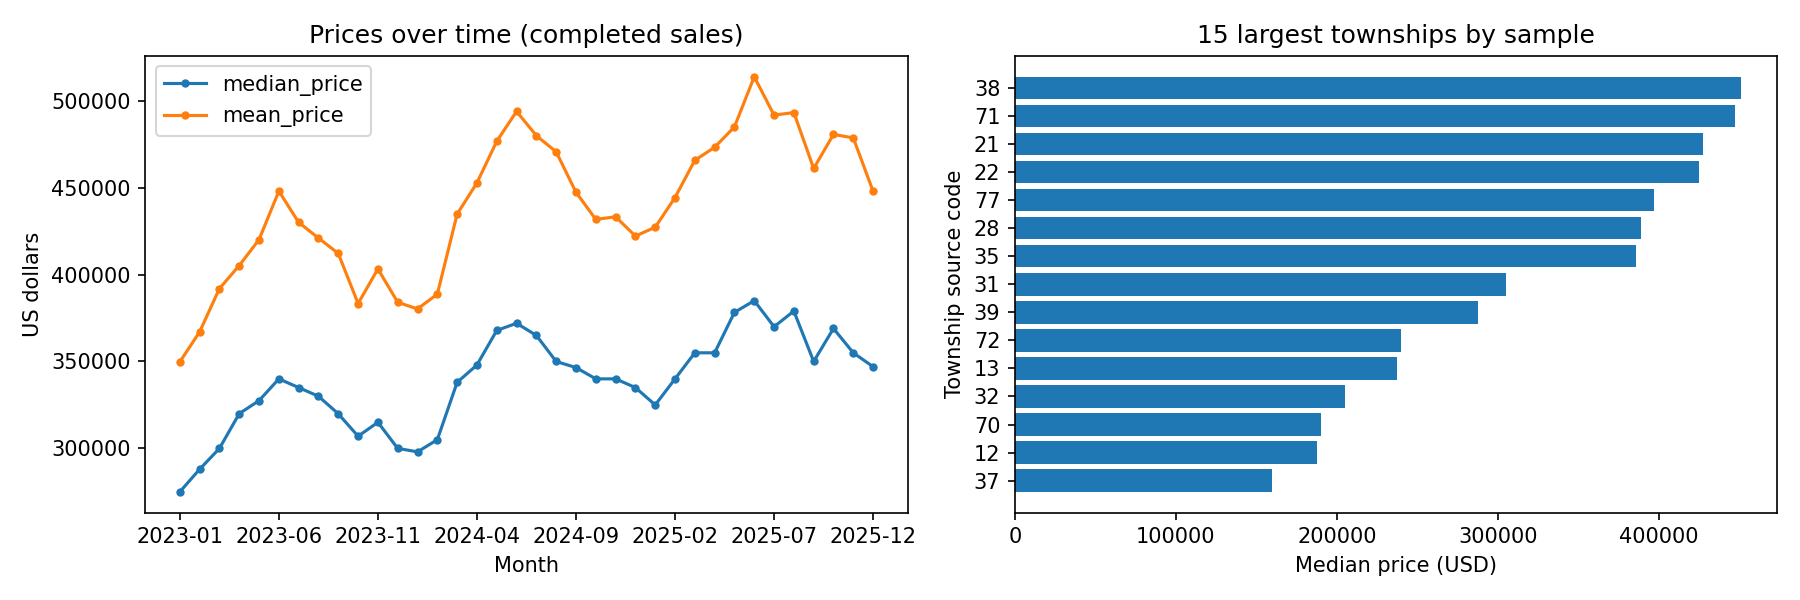

In [19]:
def evidence_notes(table, spec, out):
    model = table[table.model.eq('selected_model')].iloc[0]
    base = table[table.model.eq('baseline_median')].iloc[0]
    scenarios = pd.read_csv(out / 'weighted_error_scenarios.csv')
    notes = f'''# Analysis evidence and business interpretation\n\nSelected on 2024 validation only: {spec['family']} / {spec['feature_set']} / {spec['target']} target.\n2025 held-out sales: {int(model['n']):,}. MSE {model.MSE:,.0f} squared dollars; R² {model.R2:.3f}; MAE ${model.MAE:,.0f}.\nMain WAE ${model.WAE_main:,.0f} versus median baseline ${base.WAE_main:,.0f}.\nWithin ±20%: {model.within_20pct:.1%}; overvaluation frequency {model.overvaluation_rate:.1%}.\nAll scenario/comparator rows show a model advantage: {bool(scenarios.model_wins.all())}.\n\n4d/5a: These metrics are evidence for a supervised pilot only if local errors are acceptable;\nthey do not justify automatic tax assessments. Supply an explicit valuation date, verify\ncharacteristics and current condition, check comparable transactions, record human adjustments.\nThe source lacks unsold homes, so performance on unsold stock is not identifiable here.\n\n5b: Compare monthly/quarterly MAE, signed bias and main WAE against the held-out reference;\nmonitor township sample sizes, relative errors, missingness and unseen-category rates.\nExample proposed triggers (policy choices, NOT estimates of optimal limits): sustained\n20% WAE deterioration over two labelled periods, new-category rate over 5%, or township\nmean signed error above 10% of its median price with at least 100 sales. Investigate first;\nverify archive/input quality, then increase review or retrain on a newly frozen time split.\nDelay-based sale labels mean review and complaint records are also needed.\n\n5c: (1) Sold-only selection and old archive: prospectively sample unsold assessments for\nindependent valuer review; reconcile updated condition information before adoption.\n(2) Geographic/neighbourhood proxies and uneven area errors: audit price strata and townships\nwith adequate sample sizes; inspect local comparables and escalate weakly represented cases.\nArea Census attributes describe neighbourhoods, not individual owners.\n\n5d (under 150 words): The valuer should not automatically subtract the $30,000 repair quote\nfrom the $400,000 estimate. Repair cost need not equal the reduction in market value, and\nthe archived inputs omit the new damage. Verify the inspection, scope and reliability of\nthe quote; obtain current condition information, relevant comparable sales and, where\nneeded, an independent inspection or specialist valuation. Consider whether repairs\nrestore normal condition, whether buyers require a risk discount, and whether the model\nestimate already reflects any condition disadvantage. Review the valuation under the\ncurrent evidence and document the adjustment and uncertainty.\n\nInterpretation: permutation importance is predictive dependence under correlated inputs,\nnot a causal price effect. Log-target inverse predictions have no automatic mean-price\nunbiasedness; original-dollar validation decides whether this trade-off is worthwhile.\nMSE is sensitive to rare high prices because errors are squared; do not remove inconvenient tail errors. Weighted\nerrors encode assessment priorities and are not actual tax liabilities or monetary costs.\n\nAI appendix: Do not invent your initial views, independent checks or group contributions.\nUse data_audit/split_audit for 7a/7b, experiments and runtime for 7c, and fixed weighted-error\nresults for 7d; record this AI interaction and your own accept/change/reject decisions.\n'''
    quarters = pd.read_csv(out / 'test_by_quarter.csv')
    towns = pd.read_csv(out / 'test_three_largest_townships.csv', dtype={'meta_township_code': str})
    bands = pd.read_csv(out / 'test_by_actual_price_band.csv')
    importance = pd.read_csv(out / 'validation_permutation_importance.csv').head(8)
    notes += '\n## Specific evidence for 4b and operational examples\n\n'
    for _, row in quarters.iterrows():
        notes += (f"- {row['quarter']}: n={int(row['final_prediction_n']):,}, median sale ${row['median_actual_price']:,.0f}, "
                  f"model MAE ${row['final_prediction_MAE']:,.0f}, main WAE ${row['final_prediction_WAE_main']:,.0f}, "
                  f"signed bias ${row['final_prediction_mean_signed_error']:,.0f}.\n")
    notes += '\nThree townships selected by sample size, not by favourable performance:\n\n'
    for _, row in towns.iterrows():
        notes += (f"- Township {row['meta_township_code']}: n={int(row['final_prediction_n']):,}, "
                  f"median price ${row['median_actual_price']:,.0f}, median size {row['median_building_sf']:,.0f} sqft, "
                  f"median age {row['median_age']:,.0f}; model MAE ${row['final_prediction_MAE']:,.0f}, "
                  f"main WAE improvement {row['improvement_main_WAE_pct']:.1f}%.\n")
    notes += '\nPrice bands use development-only 10th/90th percentile cutoffs:\n\n'
    for _, row in bands.iterrows():
        notes += (f"- {row['actual_price_band']}: n={int(row['final_prediction_n']):,}, "
                  f"MAE ${row['final_prediction_MAE']:,.0f}, median APE {row['final_prediction_median_APE']:.1%}, "
                  f"signed bias ${row['final_prediction_mean_signed_error']:,.0f}.\n")
    worst = quarters.loc[quarters.final_prediction_WAE_main.idxmax()]
    highest = towns.loc[towns.final_prediction_MAE.idxmax()]
    notes += (f"\nExample A: {worst['quarter']} has the highest quarterly dollar WAE. Investigate its price level, "
              'size mix and relative errors before calling this time drift; repeat monitoring on later labels.\n'
              f"Example B: among the three largest townships, {highest['meta_township_code']} has the highest dollar MAE. "
              'Prioritise local comparable-sale review there, checking price levels and housing mix rather than '
              'assuming its relative accuracy is necessarily worst.\n'
              'Example C: an unusually expensive or visibly damaged home requires additional valuer review; '
              'price-tail errors and unrecorded condition mean a single automated point estimate is insufficient.\n')
    notes += '\nTop validation permutation dependencies (increase in main WAE, dollars):\n\n'
    for _, row in importance.iterrows():
        notes += f"- {row['feature']}: ${row['increase_in_WAE_when_permuted']:,.0f}.\n"
    (out / 'analysis_evidence.md').write_text(notes, encoding='utf-8')

eda(test,numeric,OUT,prefix='test_after_lock')
eda(df,numeric,OUT,prefix='all_sales_after_lock')
evidence_notes(test_metrics,spec,OUT)
show_image(OUT/'all_sales_after_lock_prices.png')
print((OUT/'analysis_evidence.md').read_text(encoding='utf-8'))

## 11. Independent Checks and Reproducibility

Recompute WAE, MSE, R² and MAE; verify property disjointness and that each model-family champion is the best within its family rather than relying only on output tables. These checks do not perform new model selection or change predictions based on test results.

In [27]:
# Independently recompute metrics from frozen transaction-level predictions and verify directional weights and transaction-count denominators.
assert not (set(train.property_id)&set(valid.property_id))
assert not ((set(train.property_id)|set(valid.property_id))&set(test.property_id))
assert len(comparison.query("phase != 'baseline'")) == 7
assert len(all_candidates.query("phase != 'baseline'")) >= 80
assert comparison.query("phase != 'baseline'").family.is_unique
assert len(all_candidates.query("phase == 'feature_comparison'")) == 21
for _, champion in comparison.query("phase != 'baseline'").iterrows():
    family_rows = all_candidates[all_candidates.family.eq(champion.family)]
    assert np.isclose(champion.WAE_main, family_rows.WAE_main.min())
assert np.isclose(json.loads((OUT/'model_lock.json').read_text())['validation_metrics']['WAE_main'],
                  comparison.query("phase != 'baseline'").WAE_main.min())
for _,row in scenario_results.iterrows():
    error = predictions.final_prediction.to_numpy() - predictions.sale_price.to_numpy()
    manual_wae = np.mean(np.abs(error)*np.where(error>0,row.over_weight,row.under_weight))
    assert np.isclose(manual_wae,row.model_WAE)
    baseline_col = 'baseline_prediction' if row.comparator == 'baseline_median' else 'weighted_baseline_prediction'
    base_error = predictions[baseline_col].to_numpy() - predictions.sale_price.to_numpy()
    assert np.isclose(np.mean(np.abs(base_error)*np.where(base_error>0,row.over_weight,row.under_weight)),row.baseline_WAE)
selected_row = test_metrics.loc[test_metrics.model.eq('selected_model')].iloc[0]
delta = predictions.final_prediction - predictions.sale_price
assert np.isclose(np.abs(delta).mean(),selected_row.MAE)
assert np.isclose(mean_squared_error(predictions.sale_price, predictions.final_prediction),selected_row.MSE)
assert np.isclose(r2_score(predictions.sale_price, predictions.final_prediction),selected_row.R2)
dump_json(OUT/'verification_checks.json', {'status':'passed','checks':[
    'No property overlap across the three sets','WAE manual example','Six weighted-error scenarios recomputed','MSE/R²/MAE recomputed','Family champions, overall best champion and 21 feature comparisons verified'],
    'predictions_sha256':sha256(OUT/'test_predictions_frozen.csv')})
print('全部检查通过。输出目录：',OUT.resolve())

全部检查通过。输出目录： /workspace/scratch/e6b996f3d27b/tuning_run/outputs_course_tuned


## 12. 使用结果时的边界

- 清洗不意味着可以假装历史归档已经反映新增装修或损坏；需要当前条件与人工复核。
- 学习样本只包括出售房屋，不能从测试结果证明未出售住房同样准确。
- Extreme prices are retained; MSE is especially sensitive to large tail errors. Interpret it with price-band and location results, not overall R² alone.
- 树模型对未来时间不提供线性外推；后续年份需要前瞻性监控。
- 实际模型由验证代码选出，本文不在运行前硬编码胜出模型。业务建议应依据本次输出而不是以前的结果。
- 本 Notebook 可以作为一个代码文件提交；正式报告、真实 AI 反思案例和小组贡献声明仍需小组完成。